In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import shap
import xgboost as xgb
import time

from pathlib import Path
from scipy.special import expit, logit

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

GLOBAL_SAMPLE_SIZE = 10_000
INTERACTION_SAMPLE_SIZE = 1_000

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")
FIGURES_PATH = Path("../reports/figures")

RESULTS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

In [2]:
final_artifact = joblib.load(
    MODEL_PATH / "final_fraud_model.joblib"
)

model = final_artifact["model"]
calibrator = final_artifact["calibrator"]

feature_columns = final_artifact["feature_columns"]

EPSILON = final_artifact["logit_epsilon"]

decision_threshold = final_artifact[
    "decision_threshold"
]

high_risk_threshold = final_artifact[
    "high_risk_threshold"
]

with open(
    DATA_PATH / "feature_metadata.json", "r"
) as f:

    feature_metadata = json.load(f)

target_column = feature_metadata["target_column"]

print("Decision threshold:", decision_threshold)
print("High-risk threshold:", high_risk_threshold)
print("Number of input features:", len(feature_columns))

Decision threshold: 0.16168135726258814
High-risk threshold: 0.9279876292913652
Number of input features: 12


In [3]:
preprocessor = model.named_steps["preprocessor"]

classifier = model.named_steps["classifier"]

transformed_feature_names = (
    preprocessor.get_feature_names_out().tolist()
)

transformed_feature_names

['type_CASH_IN',
 'type_CASH_OUT',
 'type_DEBIT',
 'type_PAYMENT',
 'type_TRANSFER',
 'amount',
 'log_amount',
 'recipient_is_merchant',
 'hour_sin',
 'hour_cos',
 'recipient_prior_count',
 'recipient_prior_total',
 'recipient_prior_mean',
 'recipient_hours_since_last',
 'recipient_is_new',
 'amount_to_recipient_mean']

In [4]:
booster = classifier.get_booster()

best_iteration = classifier.best_iteration

inference_booster = booster[:best_iteration + 1]

inference_booster.set_param({
    "nthread": 2
})

print("Total stored boosting rounds:",
      booster.num_boosted_rounds())

print("Boosting rounds used during inference:",
      inference_booster.num_boosted_rounds())

Total stored boosting rounds: 115
Boosting rounds used during inference: 75


In [5]:
test_df = pd.read_parquet(
    DATA_PATH / "test.parquet",
    columns=feature_columns + [
        target_column,
        "step"
    ]
).reset_index(drop=True)

X_test = test_df[feature_columns]

y_test = test_df[target_column]

print("Test shape:", test_df.shape)
print("Fraud rate:", y_test.mean())

Test shape: (123580, 14)
Fraud rate: 0.01338404272536009


In [6]:
def calibrate_probabilities(raw_probabilities):

    raw_probabilities = np.asarray(
        raw_probabilities,
        dtype=np.float64
    )

    clipped_probabilities = np.clip(
        raw_probabilities,
        EPSILON,
        1 - EPSILON
    )

    logits = logit(
        clipped_probabilities
    ).reshape(-1, 1)

    return calibrator.predict_proba(
        logits
    )[:, 1]

In [7]:
test_raw_probs = model.predict_proba(
    X_test
)[:, 1]

test_calibrated_probs = calibrate_probabilities(
    test_raw_probs
)

test_predictions = (
    test_calibrated_probs >= decision_threshold
).astype(int)

test_df["raw_probability"] = test_raw_probs

test_df["fraud_probability"] = test_calibrated_probs

test_df["prediction"] = test_predictions

In [8]:
test_df["risk_tier"] = np.select(
    [
        test_calibrated_probs >= high_risk_threshold,
        test_calibrated_probs >= decision_threshold
    ],
    [
        "High Risk",
        "Medium Risk"
    ],
    default="Low Risk"
)

In [9]:
test_df["prediction_outcome"] = np.select(
    [
        (y_test == 1) & (test_predictions == 1),
        (y_test == 0) & (test_predictions == 1),
        (y_test == 1) & (test_predictions == 0)
    ],
    [
        "True Positive",
        "False Positive",
        "False Negative"
    ],
    default="True Negative"
)

test_df["prediction_outcome"].value_counts()

prediction_outcome
True Negative     121082
True Positive       1033
False Positive       844
False Negative       621
Name: count, dtype: int64

In [10]:
def explain_transactions(X):

    X_processed = preprocessor.transform(
        X[feature_columns]
    )

    dmatrix = xgb.DMatrix(
        X_processed,
        feature_names=transformed_feature_names
    )

    contributions = inference_booster.predict(
        dmatrix,
        pred_contribs=True
    )

    shap_values = contributions[:, :-1]

    base_values = contributions[:, -1]

    raw_margins = classifier.predict(
        X_processed,
        output_margin=True
    )

    reconstructed_margins = (
        base_values + shap_values.sum(axis=1)
    )

    np.testing.assert_allclose(
        reconstructed_margins,
        raw_margins,
        rtol=1e-5,
        atol=1e-4
    )

    explanations = shap.Explanation(
        values=shap_values,
        base_values=base_values,
        data=X_processed.to_numpy(),
        feature_names=transformed_feature_names
    )

    return explanations

In [11]:
global_sample = test_df.sample(
    n=min(GLOBAL_SAMPLE_SIZE, len(test_df)),
    random_state=RANDOM_STATE
).copy()

X_global = global_sample[feature_columns]

print("Global explanation sample:", X_global.shape)

print(
    "Sample fraud prevalence:",
    global_sample[target_column].mean()
)

Global explanation sample: (10000, 12)
Sample fraud prevalence: 0.0146


In [12]:
start_time = time.perf_counter()

global_shap = explain_transactions(
    X_global
)

shap_computation_time = (
    time.perf_counter() - start_time
)

print("SHAP values shape:",
      global_shap.values.shape)

print(
    f"SHAP computation time: "
    f"{shap_computation_time:.2f} seconds"
)

SHAP values shape: (10000, 16)
SHAP computation time: 0.75 seconds


In [13]:
global_importance = pd.DataFrame({
    "feature": transformed_feature_names,

    "mean_absolute_shap": np.abs(
        global_shap.values
    ).mean(axis=0),

    "mean_shap": global_shap.values.mean(
        axis=0
    ),

    "shap_std": global_shap.values.std(
        axis=0
    )
})

global_importance = (
    global_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

global_importance["normalized_importance"] = (
    global_importance["mean_absolute_shap"]
    / global_importance["mean_absolute_shap"].sum()
)

global_importance

,feature,mean_absolute_shap,mean_shap,shap_std,normalized_importance
0,type_PAYMENT,0.622425,-0.406434,0.783637,0.165006
1,type_CASH_OUT,0.508909,-0.050994,0.544812,0.134913
2,type_TRANSFER,0.421479,-0.266873,0.429967,0.111735
3,hour_cos,0.398183,-0.037680,0.488441,0.105559
4,amount,0.389421,-0.254758,0.447654,0.103237
5,hour_sin,0.315240,-0.056140,0.434823,0.083571
6,amount_to_recipient_mean,0.255902,-0.040398,0.269815,0.067840
7,type_CASH_IN,0.240225,-0.156088,0.386809,0.063684
8,recipient_prior_count,0.203391,-0.095963,0.227296,0.053919
9,recipient_hours_since_last,0.142226,0.127158,0.088475,0.037704


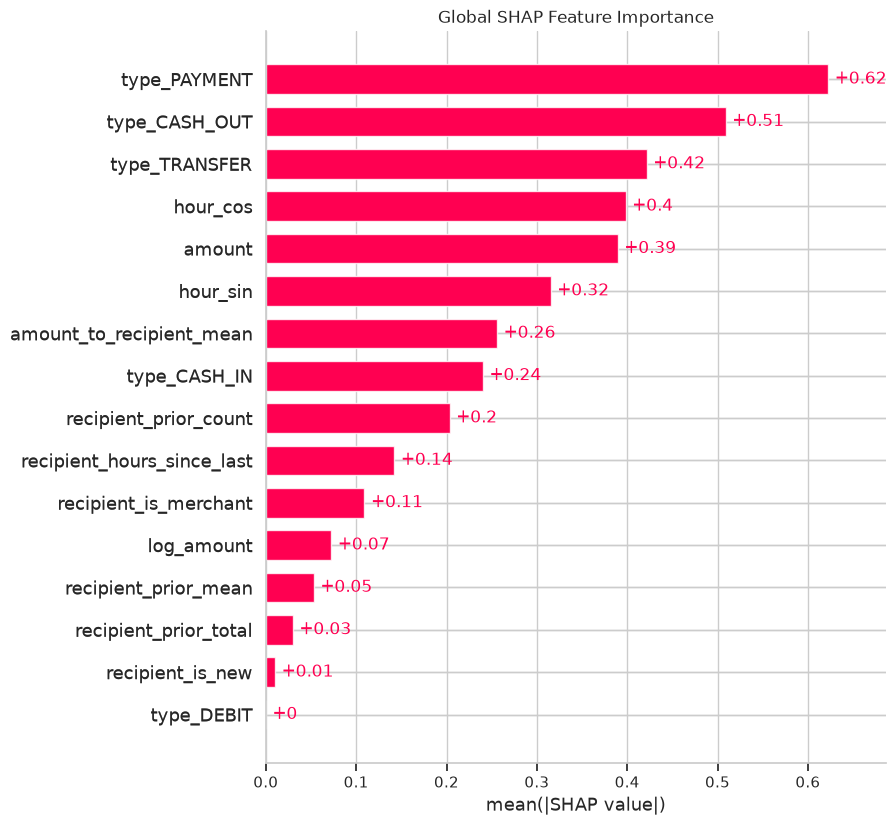

In [14]:
shap.plots.bar(
    global_shap,
    max_display=16,
    show=False
)

plt.title("Global SHAP Feature Importance")

plt.savefig(
    FIGURES_PATH / "shap_global_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [15]:
original_feature_shap = {}

for feature in feature_columns:
    if feature == "type":
        indices = [
            i
            for i, name in enumerate(
                transformed_feature_names
            )
            if name.startswith("type_")
        ]
    else:
        indices = [transformed_feature_names.index(feature)]
    original_feature_shap[feature] = (
        global_shap.values[:, indices].sum(axis=1)
    )

In [16]:
grouped_shap_df = pd.DataFrame(
    original_feature_shap
)

grouped_importance = pd.DataFrame({
    "feature": grouped_shap_df.columns,

    "mean_absolute_shap": (
        grouped_shap_df.abs().mean().values
    )
})

grouped_importance = (
    grouped_importance
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

grouped_importance

,feature,mean_absolute_shap
0,type,1.503873
1,hour_cos,0.398183
2,amount,0.389426
3,hour_sin,0.315235
4,amount_to_recipient_mean,0.255903
5,recipient_prior_count,0.203383
6,recipient_hours_since_last,0.142227
7,recipient_is_merchant,0.109180
8,log_amount,0.072419
9,recipient_prior_mean,0.053104


In [ ]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=grouped_importance,
    x="mean_absolute_shap",
    y="feature"
)

plt.title("SHAP Importance by Original Feature")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "shap_grouped_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
feature_group_importance = []

for group_name, features in (
    feature_metadata["feature_groups"].items()
):

    group_contributions = (
        grouped_shap_df[features].sum(axis=1)
    )

    feature_group_importance.append({
        "feature_group": group_name,

        "number_of_features": len(features),

        "mean_absolute_shap": (
            group_contributions.abs().mean()
        )
    })

feature_group_importance_df = (
    pd.DataFrame(feature_group_importance)
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
)

feature_group_importance_df

,feature_group,number_of_features,mean_absolute_shap
0,transaction,4,1.724051
2,behavioral,6,0.530595
1,temporal,2,0.412050


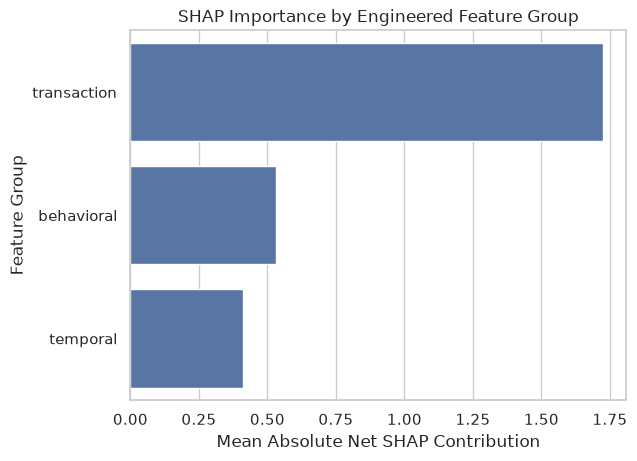

In [ ]:
sns.barplot(
    data=feature_group_importance_df,
    x="mean_absolute_shap",
    y="feature_group"
)

plt.title("SHAP Importance by Engineered Feature Group")
plt.xlabel("Mean Absolute Net SHAP Contribution")
plt.ylabel("Feature Group")
plt.show()

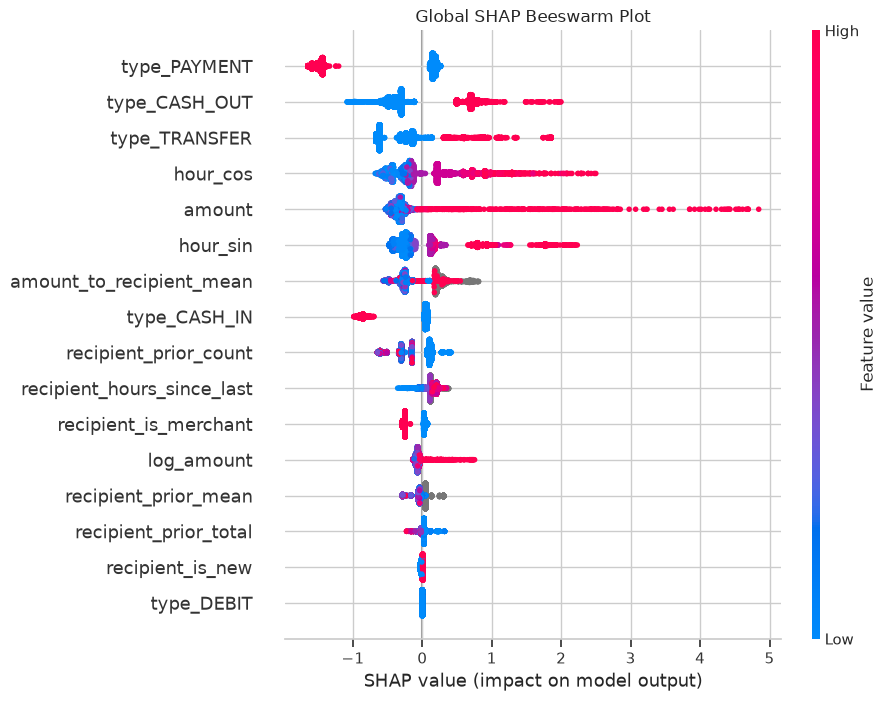

In [ ]:
shap.plots.beeswarm(
    global_shap,
    max_display=16,
    show=False
)

plt.title("Global SHAP Beeswarm Plot")

plt.savefig(
    FIGURES_PATH / "shap_beeswarm.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

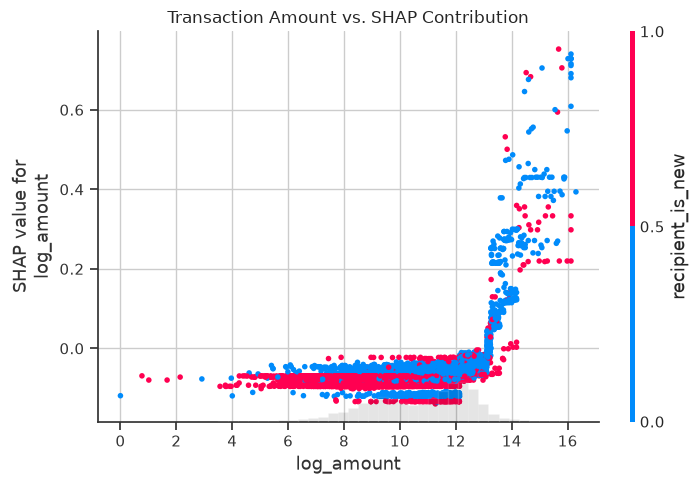

In [ ]:
shap.plots.scatter(
    global_shap[:, "log_amount"],
    color=global_shap[:, "recipient_is_new"],
    show=False
)

plt.title("Transaction Amount vs. SHAP Contribution")
plt.tight_layout()
plt.show()

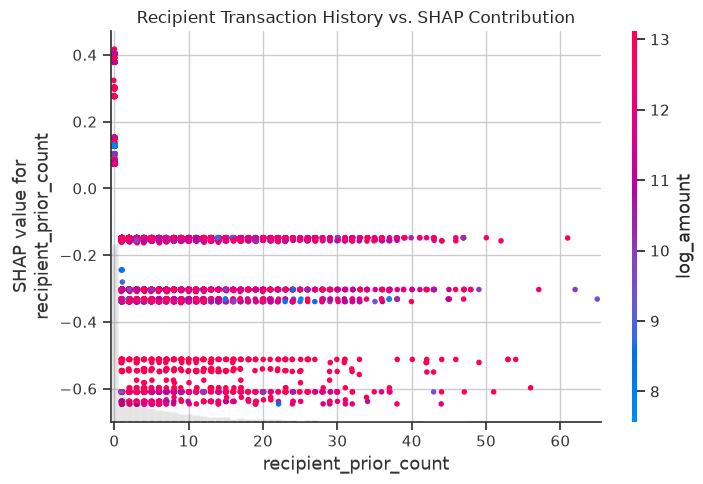

In [ ]:
shap.plots.scatter(
    global_shap[:, "recipient_prior_count"],
    color=global_shap[:, "log_amount"],
    show=False
)

plt.title("Recipient Transaction History vs. SHAP Contribution")
plt.tight_layout()
plt.show()

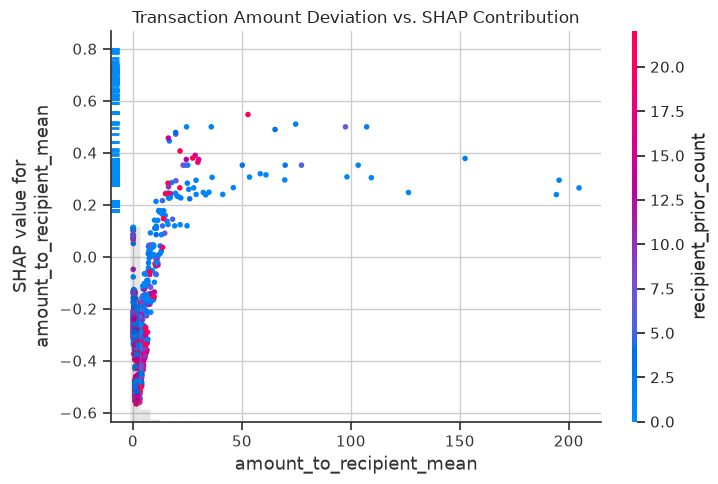

In [ ]:
shap.plots.scatter(
    global_shap[:, "amount_to_recipient_mean"],
    color=global_shap[:, "recipient_prior_count"],
    show=False
)

plt.title("Transaction Amount Deviation vs. SHAP Contribution")
plt.tight_layout()
plt.show()

In [ ]:
temporal_analysis = pd.DataFrame({
    "hour": global_sample["step"].to_numpy() % 24,

    "temporal_shap": (
        grouped_shap_df["hour_sin"]
        + grouped_shap_df["hour_cos"]
    )
})

hourly_shap = temporal_analysis.groupby(
    "hour"
)["temporal_shap"].agg(
    ["mean", "median", "std", "count"]
)

hourly_shap

,mean,median,std,count
hour,,,,
0,1.295600,1.255610,0.271433,23
1,1.683185,1.556735,0.171990,134
2,3.285577,3.330351,0.200142,13
3,3.316001,3.346883,0.238867,5
4,3.511528,3.546651,0.140110,4
5,3.540159,3.621310,0.177683,9
6,2.916400,2.884015,0.150023,15
7,2.636566,2.614878,0.166296,17
8,1.582133,1.592101,0.041096,229


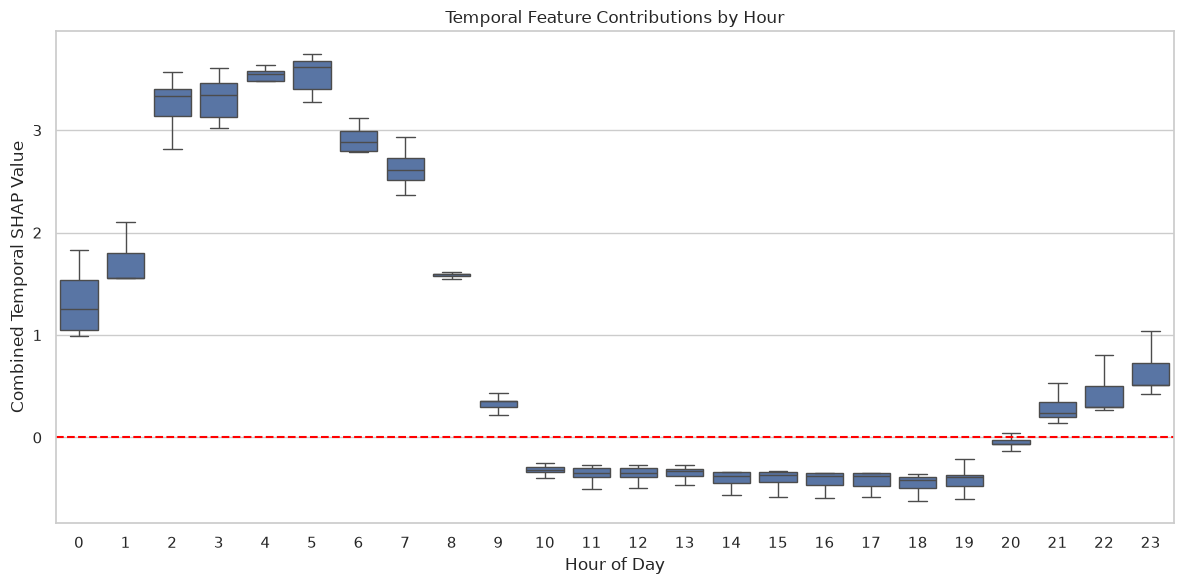

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=temporal_analysis,
    x="hour",
    y="temporal_shap",
    showfliers=False
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Temporal Feature Contributions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Combined Temporal SHAP Value")
plt.tight_layout()
plt.show()

In [ ]:
gain_scores = inference_booster.get_score(
    importance_type="gain"
)

gain_importance = pd.DataFrame({
    "feature": transformed_feature_names,

    "gain_importance": [
        gain_scores.get(feature, 0.0)
        for feature in transformed_feature_names
    ]
})

gain_importance["normalized_gain"] = (
    gain_importance["gain_importance"]
    / gain_importance["gain_importance"].sum()
)

In [ ]:
importance_comparison = global_importance.merge(
    gain_importance,
    on="feature"
)

importance_comparison["shap_rank"] = (
    importance_comparison["mean_absolute_shap"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison["gain_rank"] = (
    importance_comparison["gain_importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

importance_comparison[[
    "feature",
    "normalized_importance",
    "normalized_gain",
    "shap_rank",
    "gain_rank"
]]

,feature,normalized_importance,normalized_gain,shap_rank,gain_rank
0,type_PAYMENT,0.165006,0.024021,1,14
1,type_CASH_OUT,0.134913,0.027275,2,13
2,type_TRANSFER,0.111735,0.079500,3,5
3,hour_cos,0.105559,0.048184,4,10
4,amount,0.103237,0.107617,5,3
5,hour_sin,0.083571,0.051290,6,9
6,amount_to_recipient_mean,0.067840,0.096746,7,4
7,type_CASH_IN,0.063684,0.012853,8,15
8,recipient_prior_count,0.053919,0.068049,9,6
9,recipient_hours_since_last,0.037704,0.051377,10,8


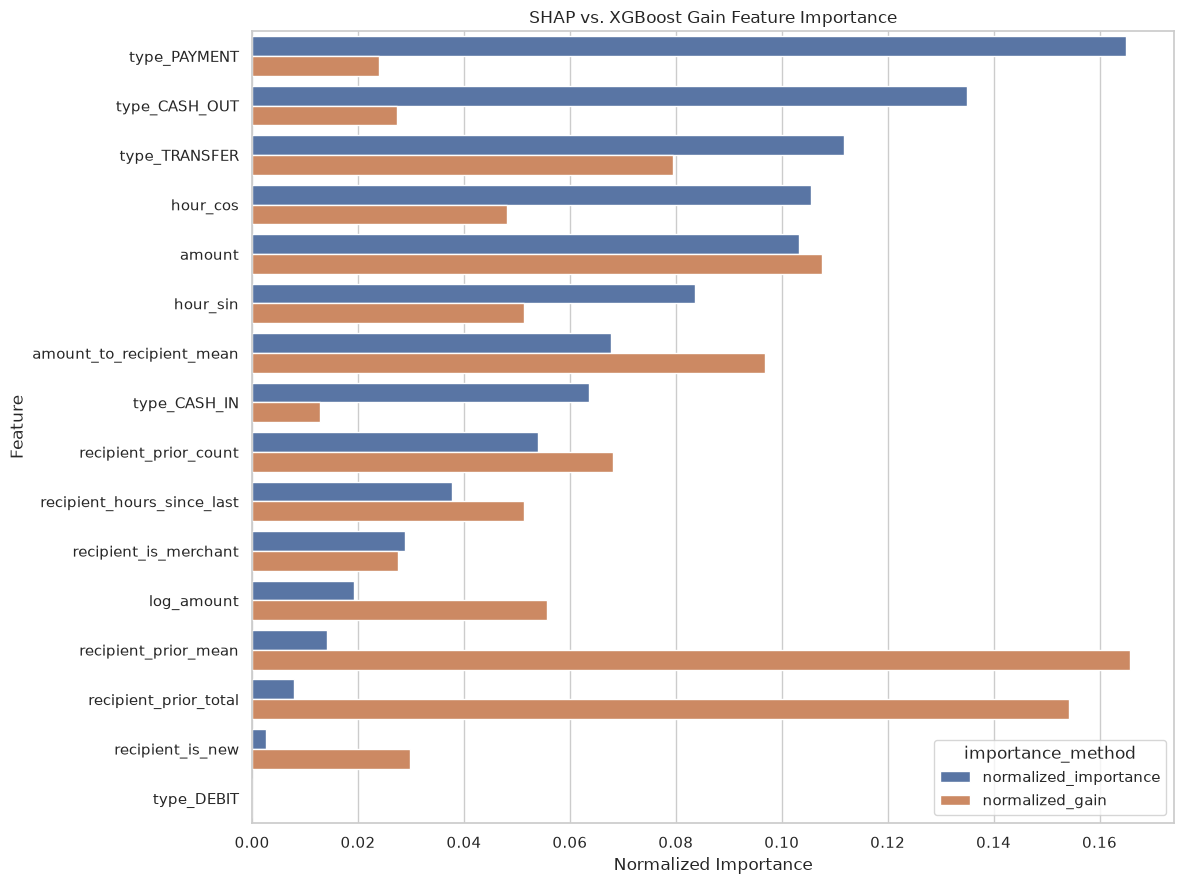

In [ ]:
importance_plot = importance_comparison.melt(
    id_vars="feature",
    value_vars=[
        "normalized_importance",
        "normalized_gain"
    ],
    var_name="importance_method",
    value_name="importance"
)

plt.figure(figsize=(12, 9))

sns.barplot(
    data=importance_plot,
    x="importance",
    y="feature",
    hue="importance_method"
)

plt.title("SHAP vs. XGBoost Gain Feature Importance")
plt.xlabel("Normalized Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
rank_correlation = importance_comparison[
    ["shap_rank", "gain_rank"]
].corr(method="spearman")

rank_correlation

,shap_rank,gain_rank
shap_rank,1.000000,-0.094118
gain_rank,-0.094118,1.000000


In [ ]:
interaction_sample = global_sample.sample(
    n=min(
        INTERACTION_SAMPLE_SIZE,
        len(global_sample)
    ),
    random_state=RANDOM_STATE
)

X_interaction = preprocessor.transform(
    interaction_sample[feature_columns]
)

interaction_matrix = xgb.DMatrix(
    X_interaction,
    feature_names=transformed_feature_names
)

In [ ]:
start_time = time.perf_counter()

interaction_values = inference_booster.predict(
    interaction_matrix,
    pred_interactions=True
)

interaction_time = (
    time.perf_counter() - start_time
)

print(
    "Interaction matrix shape:",
    interaction_values.shape
)

print(
    f"Interaction computation time: "
    f"{interaction_time:.2f} seconds"
)

Interaction matrix shape: (1000, 17, 17)
Interaction computation time: 0.06 seconds


In [ ]:
ordinary_contributions = inference_booster.predict(
    interaction_matrix,
    pred_contribs=True
)

np.testing.assert_allclose(
    interaction_values.sum(axis=2),
    ordinary_contributions,
    rtol=1e-4,
    atol=1e-4
)

print("SHAP interaction additivity checks passed.")

SHAP interaction additivity checks passed.


In [ ]:
feature_interactions = (
    interaction_values[:, :-1, :-1]
)

mean_interaction_values = np.abs(
    feature_interactions
).mean(axis=0)

interaction_df = pd.DataFrame(
    mean_interaction_values,
    index=transformed_feature_names,
    columns=transformed_feature_names
)

interaction_df

,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount,log_amount,recipient_is_merchant,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
type_CASH_IN,0.238178,0.000000,0.0,0.012094,0.000000,0.002617,0.000000,0.002849,0.004894,0.008270,0.000000,0.000000,0.000000,0.005198,0.000000,0.004304
type_CASH_OUT,0.000000,0.411798,0.0,0.005960,0.090095,0.066507,0.008612,0.003105,0.011610,0.046601,0.062830,0.000000,0.011560,0.016090,0.003834,0.017157
type_DEBIT,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
type_PAYMENT,0.012094,0.005960,0.0,0.524786,0.001288,0.022851,0.000000,0.000000,0.006992,0.018338,0.006735,0.004067,0.000000,0.038994,0.000000,0.040662
type_TRANSFER,0.000000,0.090095,0.0,0.001288,0.383576,0.063870,0.005671,0.000000,0.002765,0.012199,0.085980,0.000000,0.046200,0.007844,0.007044,0.037562
amount,0.002617,0.066507,0.0,0.022851,0.063870,0.308211,0.000000,0.003067,0.008031,0.022349,0.003344,0.017523,0.002606,0.019056,0.000000,0.011500
log_amount,0.000000,0.008612,0.0,0.000000,0.005671,0.000000,0.067144,0.000000,0.001269,0.013054,0.002425,0.001805,0.002366,0.001502,0.000000,0.011632
recipient_is_merchant,0.002849,0.003105,0.0,0.000000,0.000000,0.003067,0.000000,0.093054,0.000864,0.007868,0.003245,0.000000,0.000000,0.001524,0.000000,0.009757
hour_sin,0.004894,0.011610,0.0,0.006992,0.002765,0.008031,0.001269,0.000864,0.340689,0.101087,0.000000,0.000316,0.000000,0.000922,0.000000,0.004834
hour_cos,0.008270,0.046601,0.0,0.018338,0.012199,0.022349,0.013054,0.007868,0.101087,0.408038,0.009037,0.009600,0.000000,0.007255,0.000000,0.016971


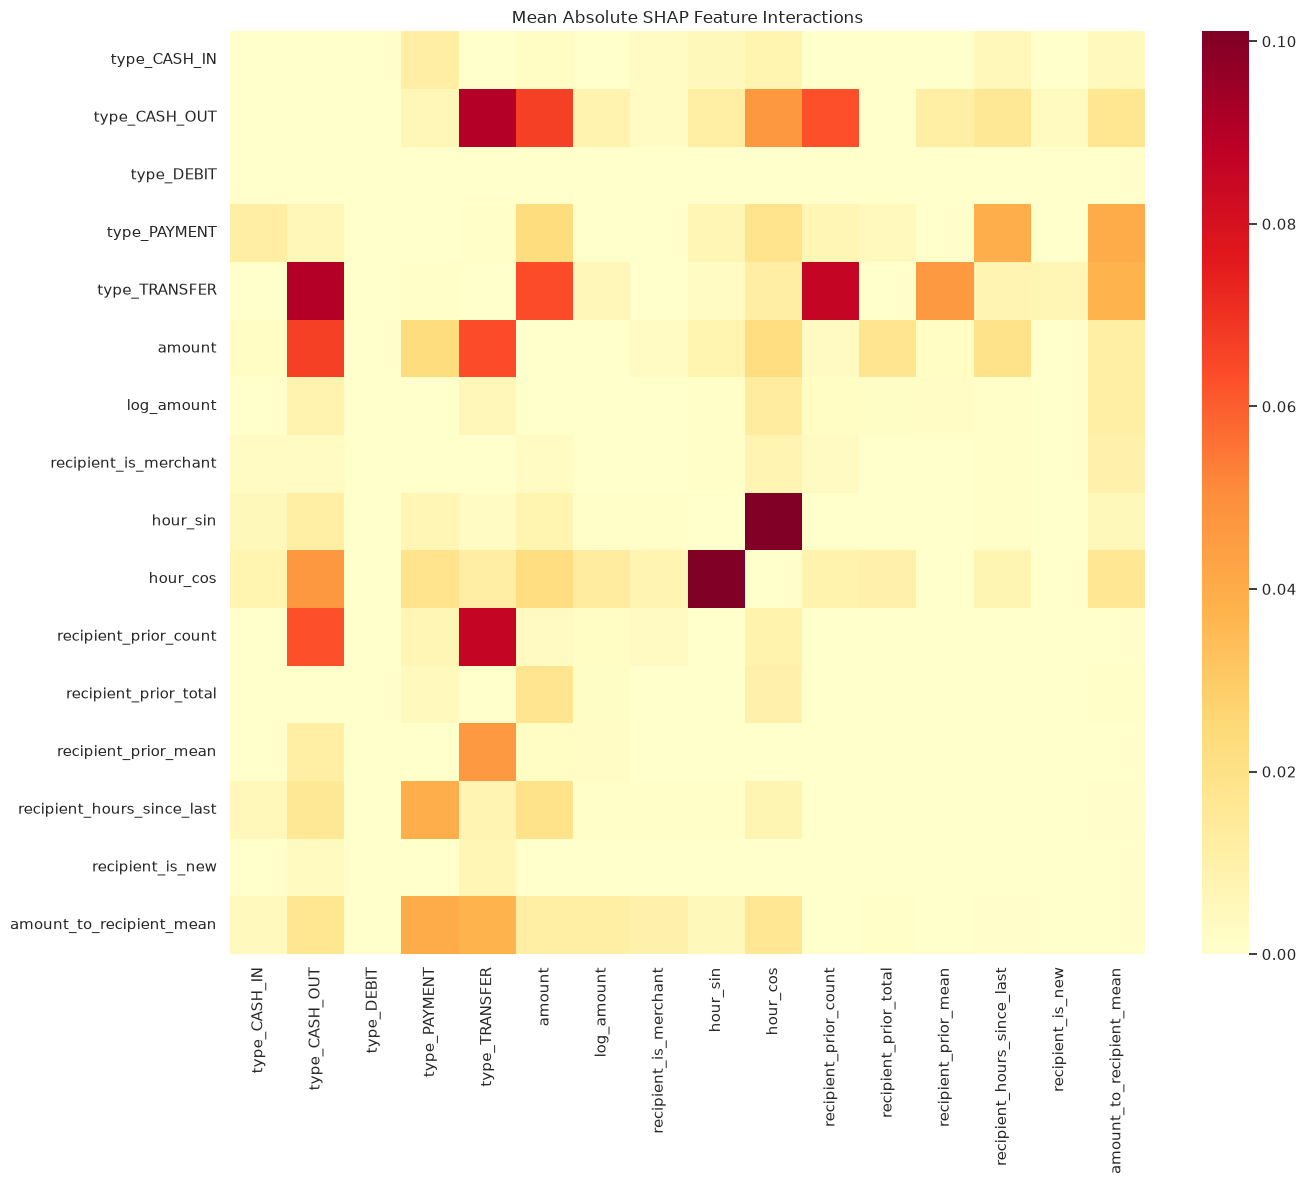

In [ ]:
interaction_heatmap = interaction_df.copy()

heatmap_values = interaction_heatmap.to_numpy(copy=True)

np.fill_diagonal(heatmap_values, 0)

interaction_heatmap = pd.DataFrame(
    heatmap_values,
    index=interaction_df.index,
    columns=interaction_df.columns
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    interaction_heatmap,
    cmap="YlOrRd"
)

plt.title("Mean Absolute SHAP Feature Interactions")
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "shap_interactions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
interaction_results = []

for i in range(len(transformed_feature_names)):

    for j in range(
        i + 1,
        len(transformed_feature_names)
    ):

        interaction_results.append({
            "feature_1": transformed_feature_names[i],

            "feature_2": transformed_feature_names[j],

            "interaction_strength": (
                2 * mean_interaction_values[i, j]
            )
        })

interaction_results_df = (
    pd.DataFrame(interaction_results)
    .sort_values(
        "interaction_strength",
        ascending=False
    )
    .reset_index(drop=True)
)

interaction_results_df.head(15)

,feature_1,feature_2,interaction_strength
0,hour_sin,hour_cos,0.202174
1,type_CASH_OUT,type_TRANSFER,0.180189
2,type_TRANSFER,recipient_prior_count,0.171960
3,type_CASH_OUT,amount,0.133014
4,type_TRANSFER,amount,0.127740
5,type_CASH_OUT,recipient_prior_count,0.125659
6,type_CASH_OUT,hour_cos,0.093203
7,type_TRANSFER,recipient_prior_mean,0.092400
8,type_PAYMENT,amount_to_recipient_mean,0.081325
9,type_PAYMENT,recipient_hours_since_last,0.077987


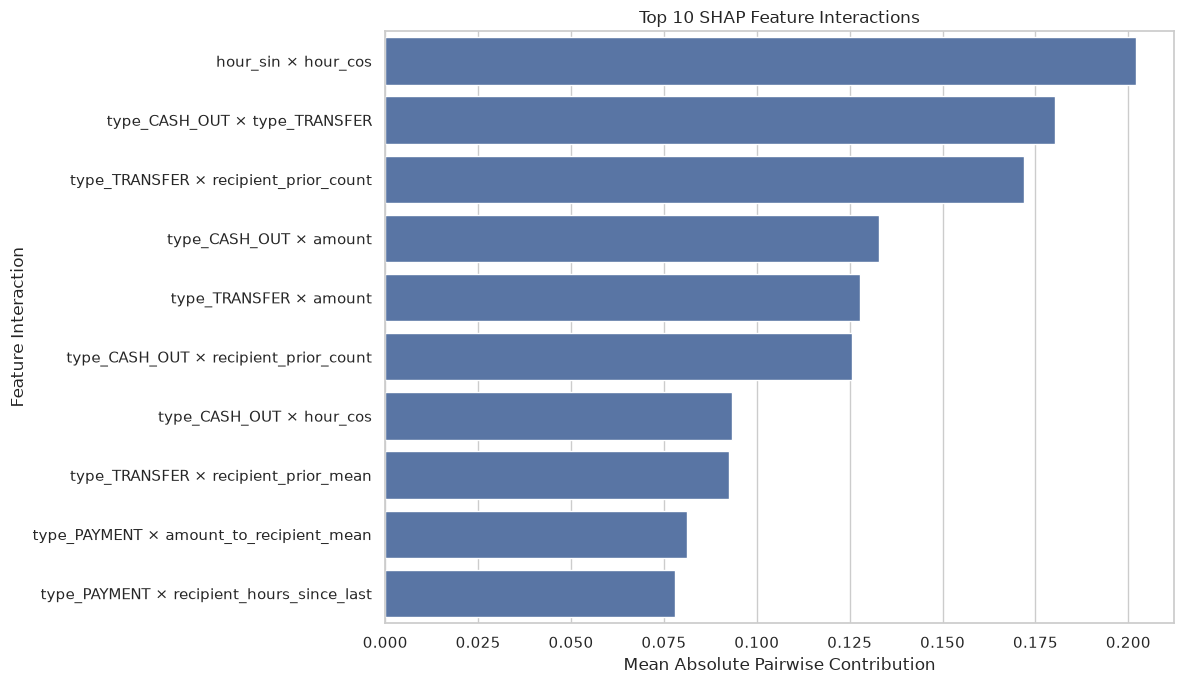

In [ ]:
top_interactions = (
    interaction_results_df.head(10).copy()
)

top_interactions["feature_pair"] = (
    top_interactions["feature_1"]
    + " × "
    + top_interactions["feature_2"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_interactions,
    x="interaction_strength",
    y="feature_pair"
)

plt.title("Top 10 SHAP Feature Interactions")
plt.xlabel("Mean Absolute Pairwise Contribution")
plt.ylabel("Feature Interaction")
plt.tight_layout()
plt.show()

In [ ]:
true_positives = test_df.loc[
    test_df["prediction_outcome"] == "True Positive"
]

false_positives = test_df.loc[
    test_df["prediction_outcome"] == "False Positive"
]

false_negatives = test_df.loc[
    test_df["prediction_outcome"] == "False Negative"
]

true_negatives = test_df.loc[
    test_df["prediction_outcome"] == "True Negative"
]

In [ ]:
case_indices = {
    "High-Value True Positive": (
        true_positives["amount"].idxmax()
    ),

    "High-Value False Positive": (
        false_positives["amount"].idxmax()
    ),

    "Highest-Value False Negative": (
        false_negatives["amount"].idxmax()
    ),

    "Near-Threshold False Negative": (
        false_negatives["fraud_probability"].idxmax()
    ),

    "Typical True Negative": (
        (
            true_negatives["amount"]
            - true_negatives["amount"].median()
        ).abs().idxmin()
    )
}

case_indices

{'High-Value True Positive': np.int64(21531),
 'High-Value False Positive': np.int64(13157),
 'Highest-Value False Negative': np.int64(52171),
 'Near-Threshold False Negative': np.int64(38986),
 'Typical True Negative': np.int64(25690)}

In [ ]:
case_df = test_df.loc[
    list(case_indices.values())
].copy()

case_df.insert(
    0,
    "case_name",
    list(case_indices.keys())
)

case_df[[
    "case_name",
    "type",
    "amount",
    "recipient_is_new",
    target_column,
    "fraud_probability",
    "risk_tier",
    "prediction_outcome"
]]

,case_name,type,amount,recipient_is_new,isFraud,fraud_probability,risk_tier,prediction_outcome
21531,High-Value True Positive,TRANSFER,10000000.00,1,1,0.783752,Medium Risk,True Positive
13157,High-Value False Positive,TRANSFER,12175598.95,0,0,0.174444,Medium Risk,False Positive
52171,Highest-Value False Negative,TRANSFER,1468304.35,1,1,0.142015,Low Risk,False Negative
38986,Near-Threshold False Negative,TRANSFER,2205.55,1,1,0.160644,Low Risk,False Negative
25690,Typical True Negative,CASH_IN,65344.65,0,0,0.000213,Low Risk,True Negative


In [ ]:
case_shap = explain_transactions(
    case_df[feature_columns]
)

print("Local SHAP shape:", case_shap.values.shape)

Local SHAP shape: (5, 16)


Case: High-Value True Positive
Transaction amount: 10,000,000.00
Calibrated fraud probability: 78.3752%
Risk tier: Medium Risk
Actual fraud label: 1


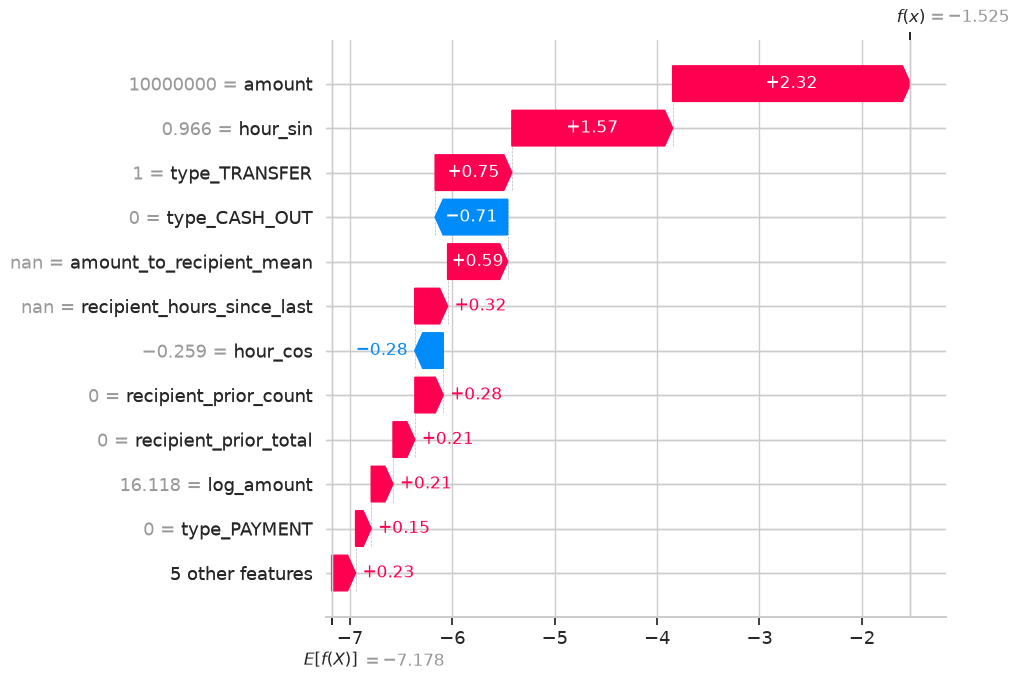

Case: High-Value False Positive
Transaction amount: 12,175,598.95
Calibrated fraud probability: 17.4444%
Risk tier: Medium Risk
Actual fraud label: 0


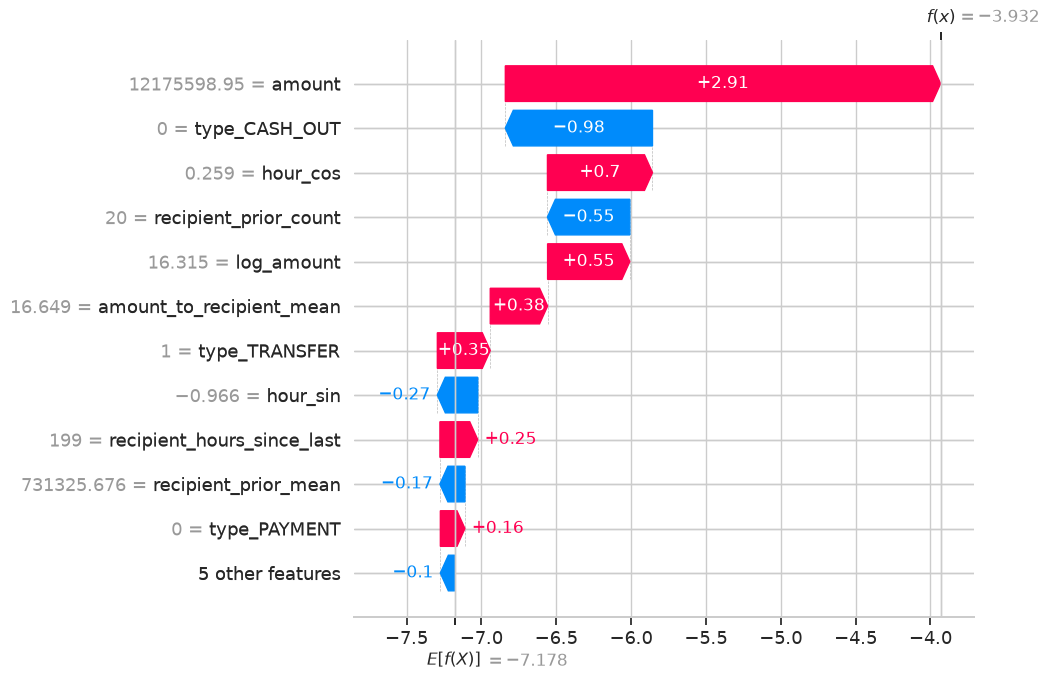

Case: Highest-Value False Negative
Transaction amount: 1,468,304.35
Calibrated fraud probability: 14.2015%
Risk tier: Low Risk
Actual fraud label: 1


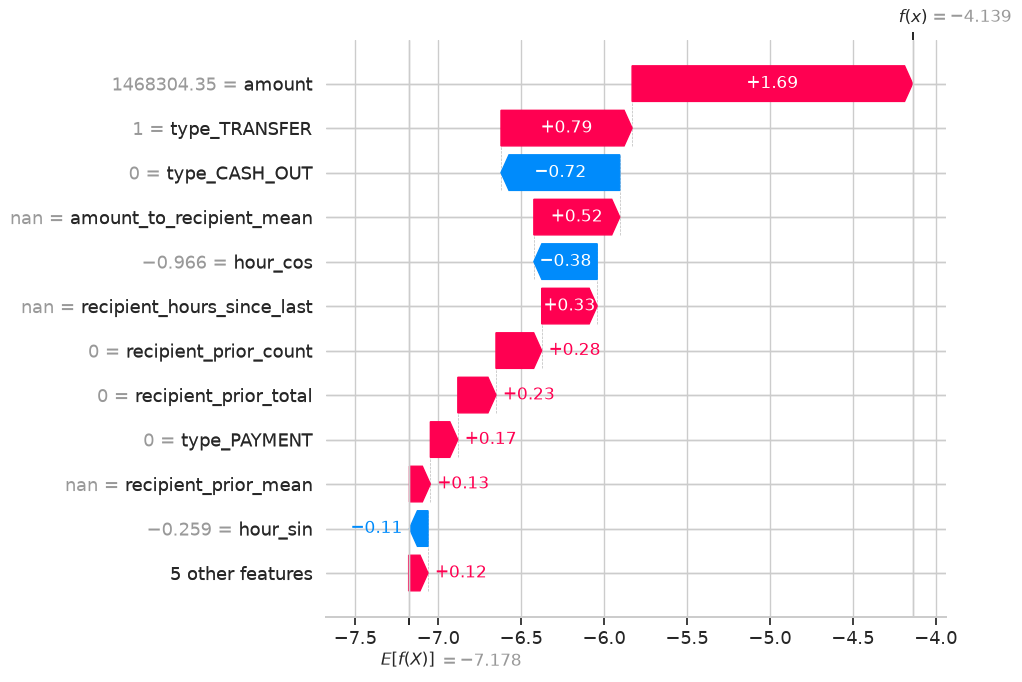

Case: Near-Threshold False Negative
Transaction amount: 2,205.55
Calibrated fraud probability: 16.0644%
Risk tier: Low Risk
Actual fraud label: 1


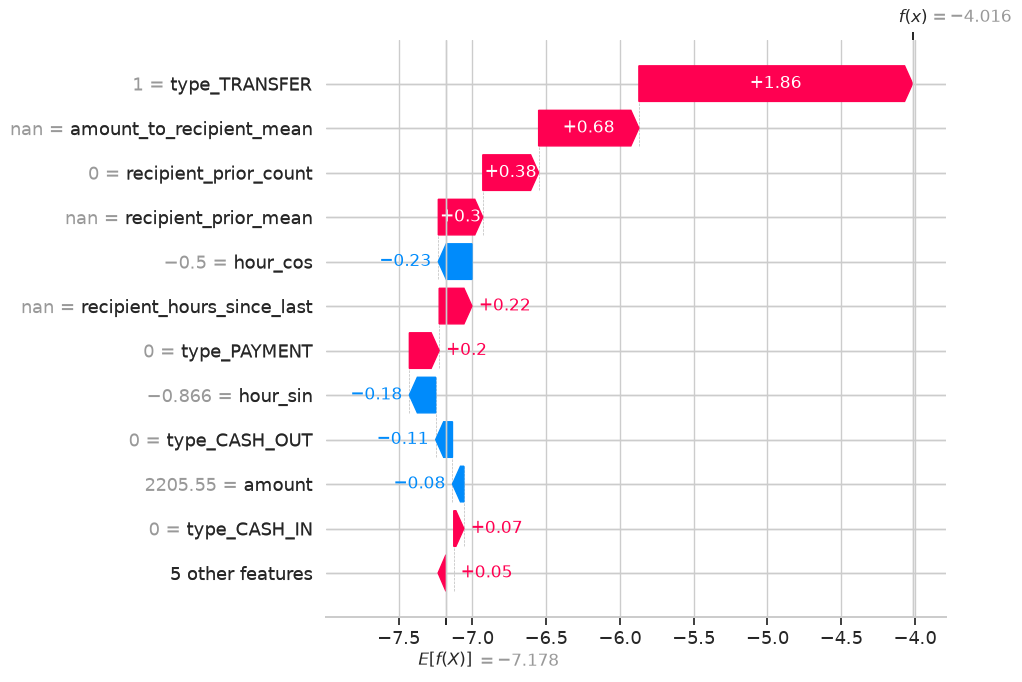

Case: Typical True Negative
Transaction amount: 65,344.65
Calibrated fraud probability: 0.0213%
Risk tier: Low Risk
Actual fraud label: 0


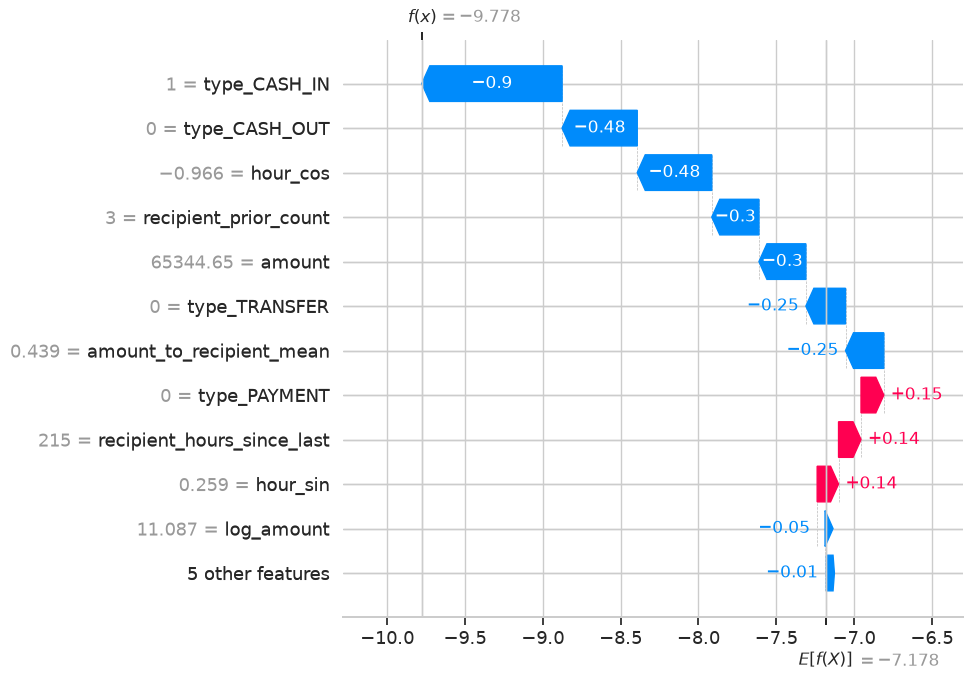

In [ ]:
for i, (case_name, transaction) in enumerate(
    case_df.iterrows()
):

    print("=" * 70)

    print("Case:", transaction["case_name"])

    print(
        "Transaction amount:",
        f"{transaction['amount']:,.2f}"
    )

    print(
        "Calibrated fraud probability:",
        f"{transaction['fraud_probability']:.4%}"
    )

    print("Risk tier:", transaction["risk_tier"])

    print(
        "Actual fraud label:",
        transaction[target_column]
    )

    shap.plots.waterfall(
        case_shap[i],
        max_display=12,
        show=False
    )

    plt.show()

In [ ]:
local_explanation_results = []

for i in range(len(case_df)):

    transaction = case_df.iloc[i]

    for j, feature in enumerate(
        transformed_feature_names
    ):

        local_explanation_results.append({
            "case_name": transaction["case_name"],

            "transaction_index": int(case_df.index[i]),

            "feature": feature,

            "feature_value": case_shap.data[i, j],

            "shap_value": case_shap.values[i, j],

            "absolute_shap": abs(
                case_shap.values[i, j]
            ),

            "direction": (
                "Increases Risk"
                if case_shap.values[i, j] > 0
                else "Decreases Risk"
                if case_shap.values[i, j] < 0
                else "Neutral"
            )
        })

local_explanations_df = pd.DataFrame(
    local_explanation_results
)

local_explanations_df

,case_name,transaction_index,feature,feature_value,shap_value,absolute_shap,direction
0,High-Value True Positive,21531,type_CASH_IN,0.000000,0.059173,0.059173,Increases Risk
1,High-Value True Positive,21531,type_CASH_OUT,0.000000,-0.708379,0.708379,Decreases Risk
2,High-Value True Positive,21531,type_DEBIT,0.000000,0.000000,0.000000,Neutral
3,High-Value True Positive,21531,type_PAYMENT,0.000000,0.152862,0.152862,Increases Risk
4,High-Value True Positive,21531,type_TRANSFER,1.000000,0.749195,0.749195,Increases Risk
...,...,...,...,...,...,...,...
75,Typical True Negative,25690,recipient_prior_total,446115.770000,0.026074,0.026074,Increases Risk
76,Typical True Negative,25690,recipient_prior_mean,148705.256667,-0.040814,0.040814,Decreases Risk
77,Typical True Negative,25690,recipient_hours_since_last,215.000000,0.144292,0.144292,Increases Risk
78,Typical True Negative,25690,recipient_is_new,0.000000,-0.015200,0.015200,Decreases Risk


In [ ]:
top_local_explanations = (
    local_explanations_df
    .sort_values(
        "absolute_shap",
        ascending=False
    )
    .groupby("case_name", sort=False)
    .head(5)
)

top_local_explanations

,case_name,transaction_index,feature,feature_value,shap_value,absolute_shap,direction
21,High-Value False Positive,13157,amount,1.217560e+07,2.907452,2.907452,Increases Risk
5,High-Value True Positive,21531,amount,1.000000e+07,2.322445,2.322445,Increases Risk
52,Near-Threshold False Negative,38986,type_TRANSFER,1.000000e+00,1.855063,1.855063,Increases Risk
37,Highest-Value False Negative,52171,amount,1.468304e+06,1.691233,1.691233,Increases Risk
8,High-Value True Positive,21531,hour_sin,9.659258e-01,1.570378,1.570378,Increases Risk
17,High-Value False Positive,13157,type_CASH_OUT,0.000000e+00,-0.982976,0.982976,Decreases Risk
64,Typical True Negative,25690,type_CASH_IN,1.000000e+00,-0.901475,0.901475,Decreases Risk
36,Highest-Value False Negative,52171,type_TRANSFER,1.000000e+00,0.790553,0.790553,Increases Risk
4,High-Value True Positive,21531,type_TRANSFER,1.000000e+00,0.749195,0.749195,Increases Risk
33,Highest-Value False Negative,52171,type_CASH_OUT,0.000000e+00,-0.716128,0.716128,Decreases Risk


In [ ]:
calibration_coefficient = float(
    calibrator.coef_[0][0]
)

calibration_intercept = float(
    calibrator.intercept_[0]
)

print(
    "Calibration coefficient:",
    calibration_coefficient
)

print(
    "Calibration intercept:",
    calibration_intercept
)

Calibration coefficient: 1.180470208807564
Calibration intercept: 3.0877332054786812


In [ ]:
calibrated_case_values = (
    calibration_coefficient
    * case_shap.values.astype(np.float64)
)

calibrated_case_base = (
    calibration_coefficient
    * case_shap.base_values.astype(np.float64)
    + calibration_intercept
)

In [ ]:
case_raw_probs = model.predict_proba(
    case_df[feature_columns]
)[:, 1].astype(np.float64)

case_raw_logits = logit(
    np.clip(
        case_raw_probs,
        EPSILON,
        1 - EPSILON
    )
)

exact_calibrated_logits = (
    calibration_coefficient * case_raw_logits
    + calibration_intercept
)

reconstructed_calibrated_logits = (
    calibrated_case_base
    + calibrated_case_values.sum(axis=1)
)

calibration_adjustment = (
    exact_calibrated_logits
    - reconstructed_calibrated_logits
)

print(
    "Maximum numerical adjustment:",
    np.abs(calibration_adjustment).max()
)

Maximum numerical adjustment: 1.9912212381179017e-06


In [ ]:
reconstructed_probs = expit(
    reconstructed_calibrated_logits
    + calibration_adjustment
)

actual_probs = calibrate_probabilities(
    case_raw_probs
)

np.testing.assert_allclose(
    reconstructed_probs,
    actual_probs,
    rtol=1e-5,
    atol=1e-7
)

print(
    "Calibrated probability reconstruction passed."
)

Calibrated probability reconstruction passed.


In [ ]:
calibrated_explanation_results = pd.DataFrame({
    "case_name": case_df["case_name"].to_numpy(),

    "calibrated_baseline_logit": (
        calibrated_case_base
    ),

    "total_feature_contribution": (
        calibrated_case_values.sum(axis=1)
    ),

    "calibration_adjustment": (
        calibration_adjustment
    ),

    "reconstructed_probability": (
        reconstructed_probs
    ),

    "actual_calibrated_probability": (
        actual_probs
    ),

    "absolute_error": np.abs(
        reconstructed_probs - actual_probs
    )
})

calibrated_explanation_results

,case_name,calibrated_baseline_logit,total_feature_contribution,calibration_adjustment,reconstructed_probability,actual_calibrated_probability,absolute_error
0,High-Value True Positive,-5.38564,6.673309,-1.573834e-07,0.783752,0.783752,0.0
1,High-Value False Positive,-5.38564,3.831186,6.281971e-07,0.174444,0.174444,0.0
2,Highest-Value False Negative,-5.38564,3.586984,-1.991221e-06,0.142015,0.142015,0.0
3,Near-Threshold False Negative,-5.38564,3.732198,-7.240787e-07,0.160644,0.160644,0.0
4,Typical True Negative,-5.38564,-3.068821,-9.020064e-07,0.000213,0.000213,0.0


In [ ]:
decision_threshold_logit = logit(
    decision_threshold
)

calibrated_explanation_results[
    "decision_margin_logit"
] = (
    exact_calibrated_logits
    - decision_threshold_logit
)

calibrated_explanation_results[
    "above_investigation_threshold"
] = (
    actual_probs >= decision_threshold
)

calibrated_explanation_results

,case_name,calibrated_baseline_logit,total_feature_contribution,calibration_adjustment,reconstructed_probability,actual_calibrated_probability,absolute_error,decision_margin_logit,above_investigation_threshold
0,High-Value True Positive,-5.38564,6.673309,-1.573834e-07,0.783752,0.783752,0.0,2.933440,True
1,High-Value False Positive,-5.38564,3.831186,6.281971e-07,0.174444,0.174444,0.0,0.091317,True
2,Highest-Value False Negative,-5.38564,3.586984,-1.991221e-06,0.142015,0.142015,0.0,-0.152887,False
3,Near-Threshold False Negative,-5.38564,3.732198,-7.240787e-07,0.160644,0.160644,0.0,-0.007672,False
4,Typical True Negative,-5.38564,-3.068821,-9.020064e-07,0.000213,0.000213,0.0,-6.808691,False


In [ ]:
error_analysis_sample = pd.concat([
    true_positives,
    false_positives,
    false_negatives,

    true_negatives.sample(
        n=min(2000, len(true_negatives)),
        random_state=RANDOM_STATE
    )
]).reset_index(drop=True)

error_analysis_sample[
    "prediction_outcome"
].value_counts()

prediction_outcome
True Negative     2000
True Positive     1033
False Positive     844
False Negative     621
Name: count, dtype: int64

In [ ]:
error_shap = explain_transactions(
    error_analysis_sample[feature_columns]
)

In [ ]:
error_shap_df = pd.DataFrame(
    error_shap.values,
    columns=transformed_feature_names,
    copy=True
)

error_shap_df["prediction_outcome"] = (
    error_analysis_sample[
        "prediction_outcome"
    ].to_numpy()
)

error_shap_df["type"] = (
    error_analysis_sample["type"].to_numpy()
)

error_shap_df["recipient_status"] = (
    error_analysis_sample[
        "recipient_is_new"
    ].to_numpy()
)

error_shap_df["is_fraud"] = (
    error_analysis_sample[
        target_column
    ].to_numpy()
)

np.testing.assert_allclose(
    error_shap_df[transformed_feature_names].to_numpy(),
    error_shap.values
)

In [ ]:
outcome_shap_summary = error_shap_df.groupby(
    "prediction_outcome"
)[transformed_feature_names].mean()

outcome_shap_summary

,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount,log_amount,recipient_is_merchant,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
prediction_outcome,,,,,,,,,,,,,,,,
False Negative,0.066500,0.402580,0.0,0.188853,0.518500,-0.148897,-0.042049,0.035704,0.040971,-0.088268,0.071603,0.028608,0.090506,0.194616,0.000537,0.170419
False Positive,0.064473,-0.245150,0.0,0.198861,1.251020,0.567354,0.032799,0.046164,0.168149,0.373840,0.257864,0.093035,0.191148,0.262917,0.006980,0.556198
True Negative,-0.169230,-0.064275,0.0,-0.438506,-0.308755,-0.290737,-0.061036,-0.075665,-0.053252,-0.064464,-0.093396,0.009859,-0.014135,0.122192,-0.005528,-0.046971
True Positive,0.061609,0.361372,0.0,0.195332,0.738358,1.788844,0.221965,0.042924,0.594308,0.957832,0.163026,0.135440,0.113941,0.268164,0.004421,0.459671


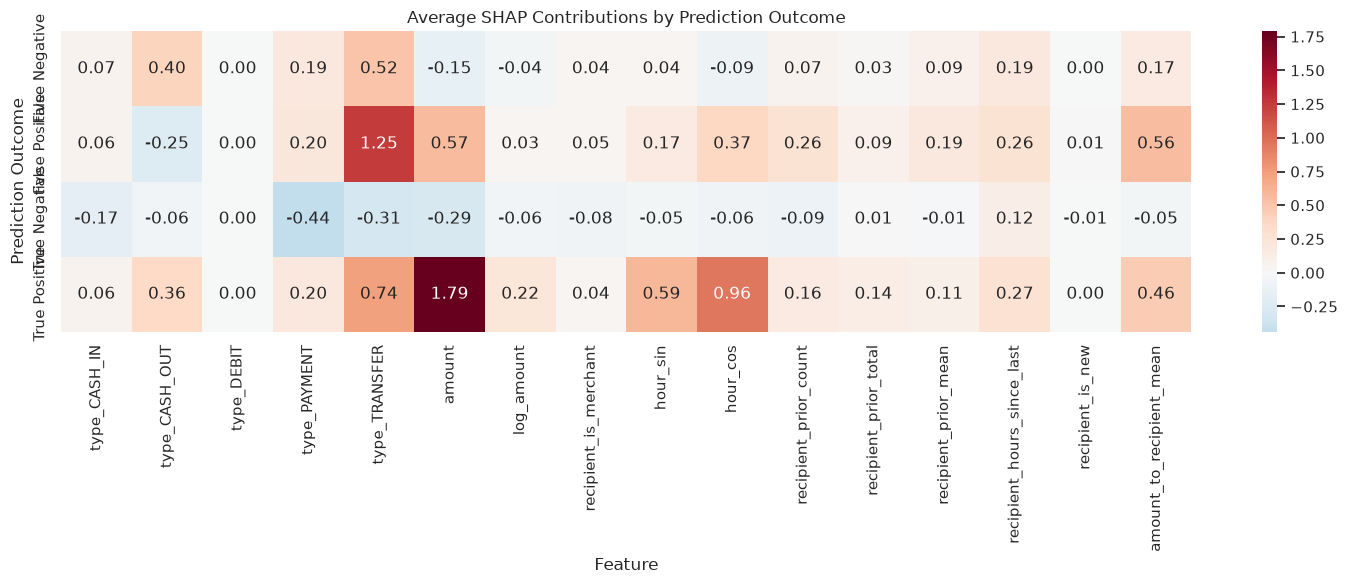

In [ ]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    outcome_shap_summary,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Average SHAP Contributions by Prediction Outcome")
plt.xlabel("Feature")
plt.ylabel("Prediction Outcome")
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "shap_error_analysis.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
missed_fraud_comparison = pd.DataFrame({
    "feature": transformed_feature_names,

    "true_positive_mean_shap": (
        outcome_shap_summary.loc[
            "True Positive"
        ].to_numpy()
    ),

    "false_negative_mean_shap": (
        outcome_shap_summary.loc[
            "False Negative"
        ].to_numpy()
    )
})

missed_fraud_comparison["contribution_difference"] = (
    missed_fraud_comparison["true_positive_mean_shap"]
    - missed_fraud_comparison["false_negative_mean_shap"]
)

missed_fraud_comparison = (
    missed_fraud_comparison
    .sort_values(
        "contribution_difference",
        ascending=False
    )
)

missed_fraud_comparison

,feature,true_positive_mean_shap,false_negative_mean_shap,contribution_difference
5,amount,1.788844,-0.148897,1.937741
9,hour_cos,0.957832,-0.088268,1.046100
8,hour_sin,0.594308,0.040971,0.553337
15,amount_to_recipient_mean,0.459671,0.170419,0.289252
6,log_amount,0.221965,-0.042049,0.264014
4,type_TRANSFER,0.738358,0.518500,0.219858
11,recipient_prior_total,0.135440,0.028608,0.106832
10,recipient_prior_count,0.163026,0.071603,0.091423
13,recipient_hours_since_last,0.268164,0.194616,0.073548
12,recipient_prior_mean,0.113941,0.090506,0.023435


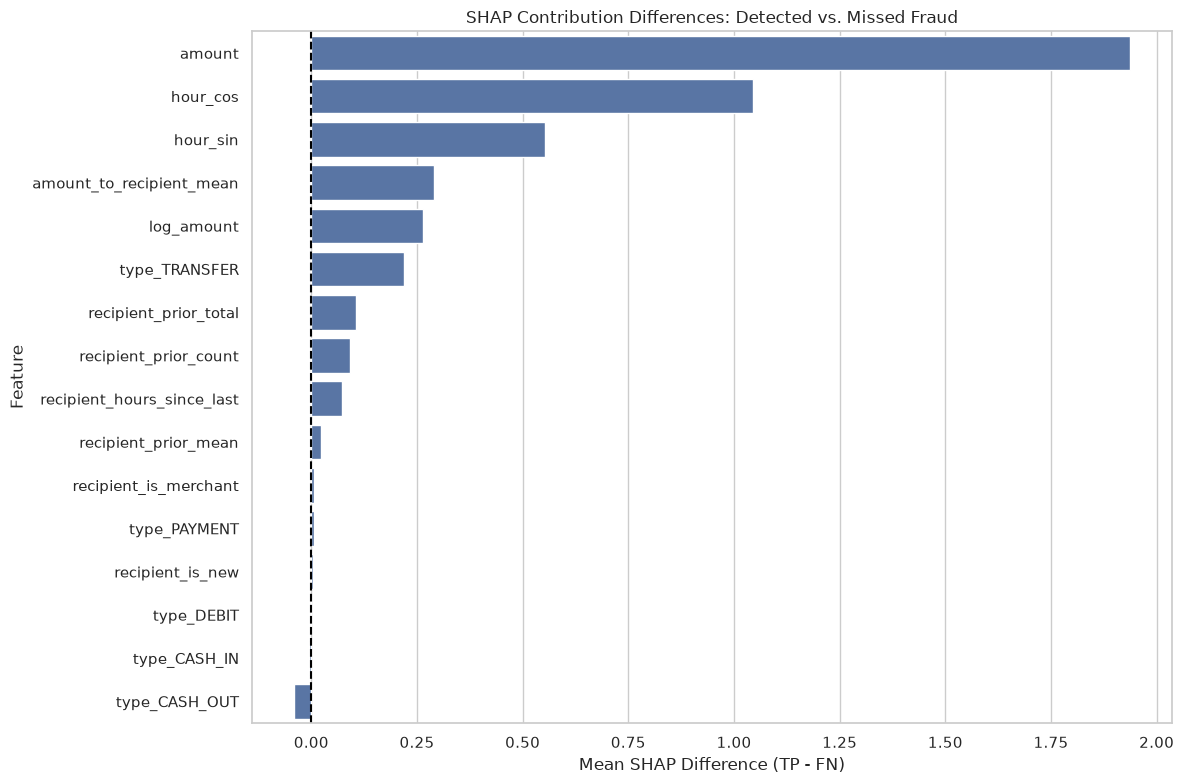

In [ ]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=missed_fraud_comparison,
    x="contribution_difference",
    y="feature"
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.title("SHAP Contribution Differences: Detected vs. Missed Fraud")
plt.xlabel("Mean SHAP Difference (TP - FN)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
fraud_shap_df = error_shap_df.loc[
    error_shap_df["is_fraud"] == 1
].copy()

transaction_type_shap = (
    fraud_shap_df
    .groupby("type", observed=True)[
        transformed_feature_names
    ]
    .mean()
)

transaction_type_shap

,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount,log_amount,recipient_is_merchant,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
type,,,,,,,,,,,,,,,,
CASH_OUT,0.063457,1.138365,0.0,0.183157,-0.073476,1.356529,0.181246,0.036153,0.390595,0.586401,-0.089496,0.055774,-0.015265,0.203731,-0.005244,0.032934
TRANSFER,0.063434,-0.384678,0.0,0.202642,1.385099,0.766096,0.064434,0.044274,0.382517,0.543739,0.346898,0.134886,0.225549,0.277369,0.011170,0.669207


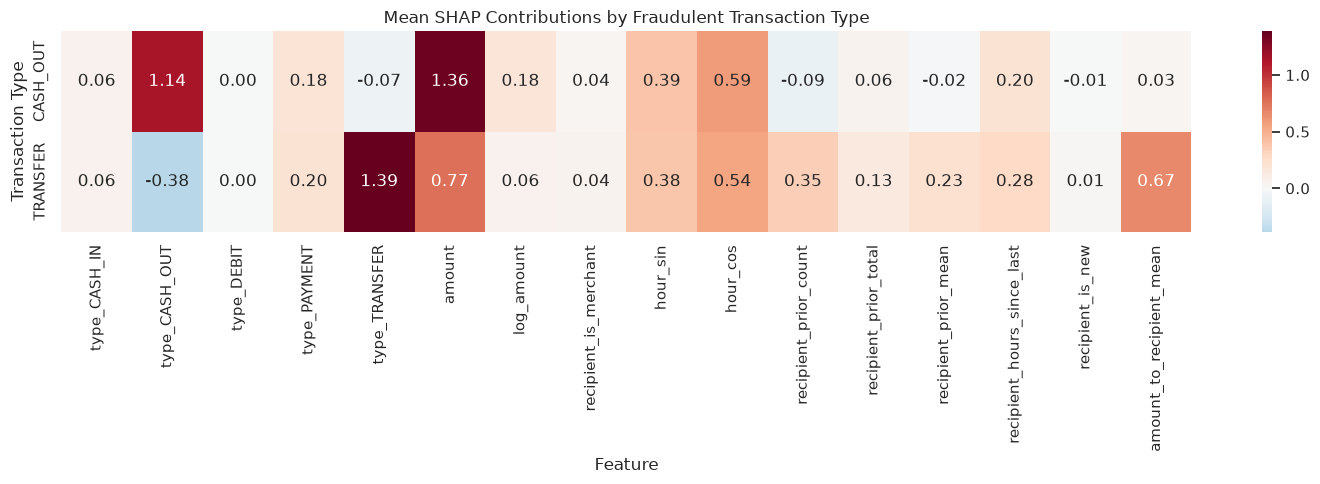

In [ ]:
plt.figure(figsize=(15, 5))

sns.heatmap(
    transaction_type_shap,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Mean SHAP Contributions by Fraudulent Transaction Type")
plt.xlabel("Feature")
plt.ylabel("Transaction Type")
plt.tight_layout()
plt.show()

In [ ]:
recipient_shap = fraud_shap_df.groupby(
    "recipient_status"
)[transformed_feature_names].mean()

recipient_shap = recipient_shap.rename(
    index={
        0: "Existing Recipient",
        1: "New Recipient"
    }
)

recipient_shap

,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount,log_amount,recipient_is_merchant,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
recipient_status,,,,,,,,,,,,,,,,
Existing Recipient,0.063542,1.172709,0.0,0.175238,-0.033688,1.253645,0.167172,0.034572,0.392236,0.568589,-0.153118,0.023361,-0.030238,0.185620,-0.008205,-0.103903
New Recipient,0.063390,-0.077397,0.0,0.202980,1.049344,0.951539,0.097537,0.043433,0.383314,0.563062,0.289549,0.136406,0.182411,0.271901,0.009337,0.610746


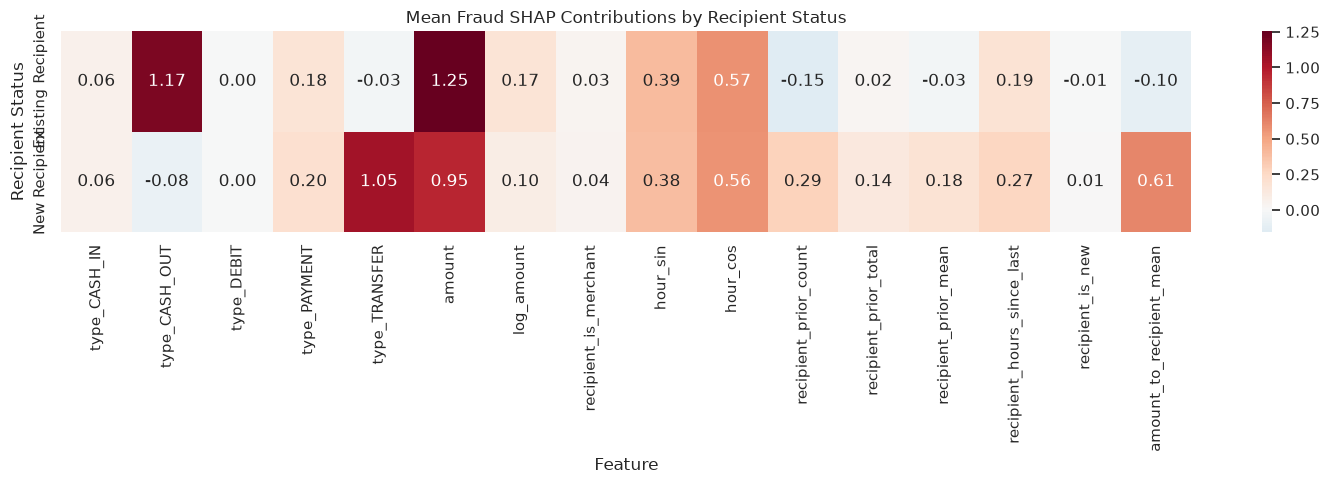

In [ ]:
plt.figure(figsize=(15, 5))

sns.heatmap(
    recipient_shap,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("Mean Fraud SHAP Contributions by Recipient Status")
plt.xlabel("Feature")
plt.ylabel("Recipient Status")
plt.tight_layout()
plt.show()

In [ ]:
subgroup_shap_summary = fraud_shap_df.groupby(
    [
        "type",
        "prediction_outcome"
    ],
    observed=True
)[transformed_feature_names].mean()

subgroup_shap_summary

type_CASH_IN  type_CASH_OUT  type_DEBIT  \
type     prediction_outcome                                            
CASH_OUT False Negative          0.065374       0.746236         0.0   
         True Positive           0.061745       1.488320         0.0   
TRANSFER False Negative          0.068399      -0.177619         0.0   
         True Positive           0.061510      -0.464931         0.0   

                             type_PAYMENT  type_TRANSFER    amount  \
type     prediction_outcome                                          
CASH_OUT False Negative          0.185570      -0.158099 -0.280488   
         True Positive           0.181004       0.002047  2.817482   
TRANSFER False Negative          0.194396       1.660810  0.073270   
         True Positive           0.205838       1.278238  1.034624   

                             log_amount  recipient_is_merchant  hour_sin  \
type     prediction_outcome                                                
CASH_OUT False Negative       -0.053696               0.034735  0.101862   
         True Positive         0.390919               0.037418  0.648274   
TRANSFER False Negative       -0.022386               0.037340 -0.061831   
         True Positive         0.098083               0.046961  0.554739   

                             hour_cos  recipient_prior_count  \
type     prediction_outcome                                    
CASH_OUT False Negative      0.070009              -0.099810   
         True Positive       1.047254              -0.080292   
TRANSFER False Negative     -0.355490               0.361001   
         True Positive       0.892266               0.341431   

                             recipient_prior_total  recipient_prior_mean  \
type     prediction_outcome                                                
CASH_OUT False Negative                   0.015415             -0.018049   
         True Positive                    0.091791             -0.012780   
TRANSFER False Negative                   0.050882              0.273780   
         True Positive                    0.167444              0.206856   

                             recipient_hours_since_last  recipient_is_new  \
type     prediction_outcome                                                 
CASH_OUT False Negative                        0.167577         -0.005760   
         True Positive                         0.235997         -0.004784   
TRANSFER False Negative                        0.240266          0.011170   
         True Positive                         0.291749          0.011170   

                             amount_to_recipient_mean  
type     prediction_outcome                            
CASH_OUT False Negative                     -0.121290  
         True Positive                       0.170571  
TRANSFER False Negative                      0.662916  
         True Positive                       0.671646

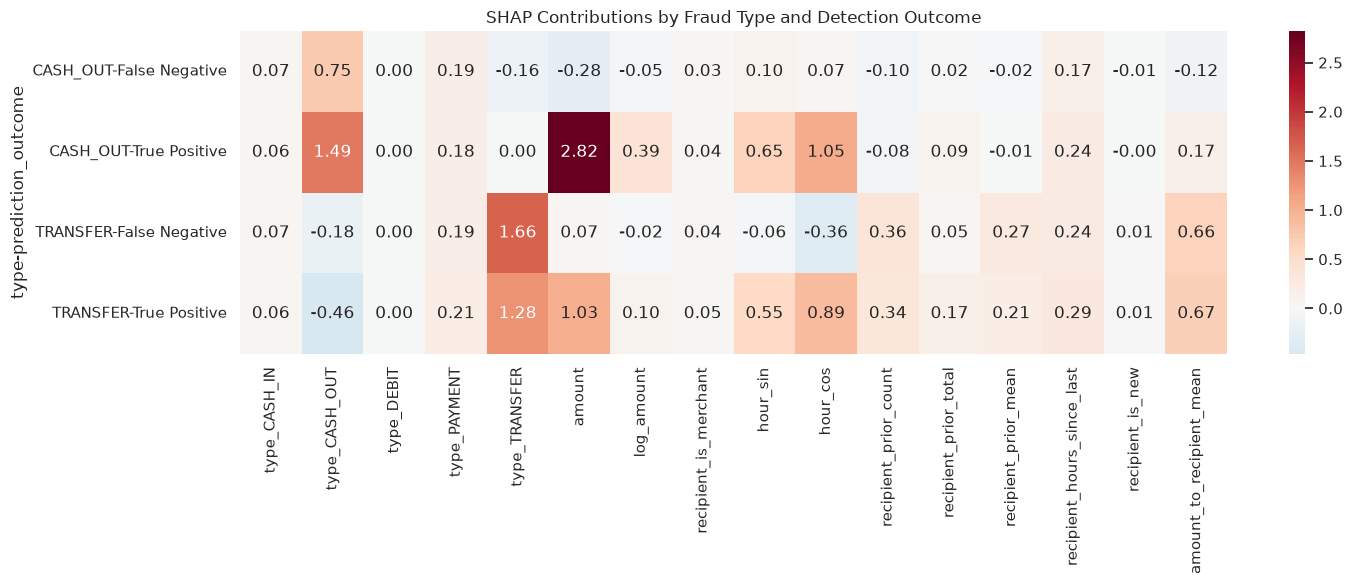

In [ ]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    subgroup_shap_summary,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("SHAP Contributions by Fraud Type and Detection Outcome")
plt.tight_layout()
plt.show()

In [ ]:
def explain_single_transaction(
    transaction,
    top_n=5
):

    X = transaction[feature_columns]

    if len(X) != 1:
        raise ValueError(
            "Expected exactly one transaction."
        )

    raw_probability = float(
        model.predict_proba(X)[0, 1]
    )

    calibrated_probability = float(
        calibrate_probabilities(
            [raw_probability]
        )[0]
    )

    explanation = explain_transactions(X)

    contributions = []

    # Aggregate encoded categories into original features
    for feature in feature_columns:

        if feature == "type":

            indices = [
                i
                for i, name in enumerate(
                    transformed_feature_names
                )
                if name.startswith("type_")
            ]

        else:

            indices = [
                transformed_feature_names.index(feature)
            ]

        shap_value = float(
            explanation.values[0, indices].sum()
        )

        original_value = X.iloc[0][feature]

        if pd.isna(original_value):
            original_value = None

        elif isinstance(original_value, np.generic):
            original_value = original_value.item()

        contributions.append({
            "feature": feature,

            "feature_value": original_value,

            "shap_value": shap_value,

            "direction": (
                "increases_risk"
                if shap_value > 0
                else "decreases_risk"
                if shap_value < 0
                else "neutral"
            )
        })

    contributions.sort(
        key=lambda item: abs(item["shap_value"]),
        reverse=True
    )

    if calibrated_probability >= high_risk_threshold:

        risk_tier = "High Risk"

    elif calibrated_probability >= decision_threshold:

        risk_tier = "Medium Risk"

    else:

        risk_tier = "Low Risk"

    return {
        "raw_probability": raw_probability,

        "fraud_probability": calibrated_probability,

        "risk_tier": risk_tier,

        "requires_investigation": (
            calibrated_probability >= decision_threshold
        ),

        "decision_threshold": float(
            decision_threshold
        ),

        "explanation_method": "TreeSHAP",

        "explanation_units": "raw_log_odds",

        "top_contributing_features": contributions[:top_n]
    }

In [ ]:
example_transaction = case_df.iloc[[0]]

example_explanation = explain_single_transaction(
    example_transaction,
    top_n=5
)

print(
    json.dumps(
        example_explanation,
        indent=4,
        allow_nan=False
    )
)

{
    "raw_probability": 0.17874540388584137,
    "fraud_probability": 0.7837523437439209,
    "risk_tier": "Medium Risk",
    "requires_investigation": true,
    "decision_threshold": 0.16168135726258814,
    "explanation_method": "TreeSHAP",
    "explanation_units": "raw_log_odds",
    "top_contributing_features": [
        {
            "feature": "amount",
            "feature_value": 10000000.0,
            "shap_value": 2.3224446773529053,
            "direction": "increases_risk"
        },
        {
            "feature": "hour_sin",
            "feature_value": 0.9659258262890683,
            "shap_value": 1.5703784227371216,
            "direction": "increases_risk"
        },
        {
            "feature": "amount_to_recipient_mean",
            "feature_value": null,
            "shap_value": 0.5867045521736145,
            "direction": "increases_risk"
        },
        {
            "feature": "recipient_hours_since_last",
            "feature_value": null,
           

In [ ]:
global_reconstructed_margins = (
    global_shap.base_values
    + global_shap.values.sum(axis=1)
)

global_raw_probabilities = model.predict_proba(
    X_global
)[:, 1]

global_reconstructed_probs = expit(
    global_reconstructed_margins
)

probability_errors = np.abs(
    global_raw_probabilities
    - global_reconstructed_probs
)

pd.Series(probability_errors).describe()

count    1.000000e+04
mean     1.439701e-09
std      1.303653e-08
min      0.000000e+00
25%      4.001777e-11
50%      5.820766e-11
75%      3.929017e-10
max      4.470348e-07
dtype: float64

In [ ]:
np.testing.assert_allclose(
    global_reconstructed_probs,
    global_raw_probabilities,
    rtol=1e-4,
    atol=1e-5
)

print("Global probability reconstruction passed.")

Global probability reconstruction passed.


In [ ]:
np.testing.assert_allclose(
    grouped_shap_df.sum(axis=1).to_numpy(),
    global_shap.values.sum(axis=1),
    rtol=1e-5,
    atol=1e-4
)

print("Grouped SHAP additivity passed.")

Grouped SHAP additivity passed.


In [ ]:
assert np.isclose(
    example_explanation["fraud_probability"],
    example_transaction[
        "fraud_probability"
    ].iloc[0]
)

assert (
    example_explanation["risk_tier"]
    == example_transaction["risk_tier"].iloc[0]
)

print("Transaction explanation consistency passed.")

Transaction explanation consistency passed.


In [ ]:
explanation_checks = {
    "global_additivity_passed": True,

    "grouped_additivity_passed": True,

    "interaction_additivity_passed": True,

    "calibrated_probability_reconstruction_passed": True,

    "transaction_explanation_consistency_passed": True,

    "mean_probability_reconstruction_error": float(
        probability_errors.mean()
    ),

    "max_probability_reconstruction_error": float(
        probability_errors.max()
    )
}

explanation_checks

{'global_additivity_passed': True,
 'grouped_additivity_passed': True,
 'interaction_additivity_passed': True,
 'calibrated_probability_reconstruction_passed': True,
 'transaction_explanation_consistency_passed': True,
 'mean_probability_reconstruction_error': 1.4397010250633002e-09,
 'max_probability_reconstruction_error': 4.470348358154297e-07}

In [ ]:
global_importance.to_csv(
    RESULTS_PATH / "shap_global_importance.csv",
    index=False
)

grouped_importance.to_csv(
    RESULTS_PATH / "shap_grouped_importance.csv",
    index=False
)

feature_group_importance_df.to_csv(
    RESULTS_PATH / "shap_feature_group_importance.csv",
    index=False
)

importance_comparison.to_csv(
    RESULTS_PATH / "shap_gain_comparison.csv",
    index=False
)

In [ ]:
interaction_results_df.to_csv(
    RESULTS_PATH / "shap_interaction_results.csv",
    index=False
)

In [ ]:
local_explanations_df.to_csv(
    RESULTS_PATH / "shap_local_explanations.csv",
    index=False
)

case_df[[
    "case_name",
    "type",
    "amount",
    target_column,
    "raw_probability",
    "fraud_probability",
    "risk_tier",
    "prediction_outcome"
]].to_csv(
    RESULTS_PATH / "shap_case_studies.csv",
    index=False
)

calibrated_explanation_results.to_csv(
    RESULTS_PATH / "shap_calibrated_explanations.csv",
    index=False
)

In [ ]:
outcome_shap_summary.to_csv(
    RESULTS_PATH / "shap_outcome_analysis.csv"
)

missed_fraud_comparison.to_csv(
    RESULTS_PATH / "shap_missed_fraud_analysis.csv",
    index=False
)

transaction_type_shap.to_csv(
    RESULTS_PATH / "shap_transaction_type_analysis.csv"
)

recipient_shap.to_csv(
    RESULTS_PATH / "shap_recipient_analysis.csv"
)

subgroup_shap_summary.to_csv(
    RESULTS_PATH / "shap_subgroup_analysis.csv"
)

In [ ]:
explainability_metadata = {
    "model_type": "XGBoost",

    "explanation_method": "TreeSHAP",

    "implementation": "xgboost_native_contributions",

    "explanation_units": "raw_log_odds",

    "evaluation_dataset": "held_out_test",

    "global_sample_size": len(global_sample),

    "interaction_sample_size": len(interaction_sample),

    "error_analysis_sample_size": len(
        error_analysis_sample
    ),

    "original_features": feature_columns,

    "transformed_features": transformed_feature_names,

    "boosting_rounds_explained": (
        inference_booster.num_boosted_rounds()
    ),

    "calibration_coefficient": (
        calibration_coefficient
    ),

    "calibration_intercept": (
        calibration_intercept
    ),

    "decision_threshold": float(
        decision_threshold
    ),

    "high_risk_threshold": float(
        high_risk_threshold
    ),

    "global_shap_computation_seconds": (
        shap_computation_time
    ),

    "interaction_computation_seconds": (
        interaction_time
    ),

    "shap_version": shap.__version__,

    "xgboost_version": xgb.__version__,

    "random_state": RANDOM_STATE,

    "model_modified": False,

    "decision_policy_modified": False,

    "reliability_checks": explanation_checks
}

with open(
    MODEL_PATH / "explainability_metadata.json",
    "w"
) as f:

    json.dump(
        explainability_metadata,
        f,
        indent=4,
        allow_nan=False
    )

## Key Findings

### Explainability Methodology
- Implemented TreeSHAP using XGBoost's native feature contribution functionality.
- Used the SHAP library to visualize global and transaction-level explanations.
- Reused the finalized calibrated XGBoost model without retraining or modifying its parameters.
- Preserved the cost-sensitive investigation threshold of approximately 0.161681.
- Preserved the high-risk investigation threshold of approximately 0.927988.
- Retained all 12 leakage-controlled predictive features.
- Explained all 16 transformed features generated by the fitted preprocessing pipeline.
- Expressed standard SHAP contributions in raw model log-odds units.
- Used the held-out test dataset for post-evaluation model diagnostics rather than additional model development.

### Model Consistency and Early Stopping
- The trained XGBoost artifact contained 115 stored boosting rounds.
- The finalized prediction pipeline used the first 75 boosting rounds selected through early stopping.
- Extracted the selected boosting rounds before calculating SHAP contributions.
- Ensured that explanations corresponded to the actual classifier used during inference.
- Reproduced the final held-out test confusion matrix.

| Prediction Outcome | Transactions |
|---|---:|
| True Negative | 121,082 |
| True Positive | 1,033 |
| False Positive | 844 |
| False Negative | 621 |

- No classifier parameters, calibration parameters, or decision thresholds were modified.

### Global SHAP Feature Importance
- Randomly sampled 10,000 held-out test transactions for global SHAP analysis.
- The sampled transactions contained a fraud prevalence of 1.46%, compared with approximately 1.34% in the complete test dataset.
- Generated a SHAP contribution matrix containing 10,000 transactions and 16 transformed features.
- Calculated mean absolute SHAP values to measure the average magnitude of individual feature contributions.

| Transformed Feature | Mean Absolute SHAP | Normalized Importance |
|---|---:|---:|
| type_PAYMENT | 0.622425 | 16.50% |
| type_CASH_OUT | 0.508909 | 13.49% |
| type_TRANSFER | 0.421479 | 11.17% |
| hour_cos | 0.398183 | 10.56% |
| amount | 0.389421 | 10.32% |
| hour_sin | 0.315240 | 8.36% |
| amount_to_recipient_mean | 0.255902 | 6.78% |
| type_CASH_IN | 0.240225 | 6.37% |
| recipient_prior_count | 0.203391 | 5.39% |
| recipient_hours_since_last | 0.142226 | 3.77% |
| recipient_is_merchant | 0.109180 | 2.89% |
| log_amount | 0.072419 | 1.92% |
| recipient_prior_mean | 0.053102 | 1.41% |
| recipient_prior_total | 0.029815 | 0.79% |
| recipient_is_new | 0.010207 | 0.27% |
| type_DEBIT | 0.000000 | 0.00% |

- Transaction-type indicators represented several of the most influential transformed features.
- Transaction timing and transaction amount also contributed substantially to model predictions.
- Engineered behavioral features provided additional predictive information.
- The PAYMENT indicator exhibited the highest global SHAP importance, primarily through its contribution toward reducing fraud scores when present.
- The DEBIT indicator received zero SHAP importance and zero gain importance in the selected boosting rounds.
- High SHAP importance does not necessarily indicate a positive association with fraud because importance measures absolute contribution magnitude.

### Original Feature Importance
- Aggregated the five one-hot encoded transaction-type contributions into their original categorical feature.
- Summed encoded SHAP contributions for each transaction before calculating mean absolute importance.
- This aggregation preserved the net contribution of transaction type.

| Original Feature | Mean Absolute SHAP |
|---|---:|
| type | 1.503873 |
| hour_cos | 0.398183 |
| amount | 0.389426 |
| hour_sin | 0.315235 |
| amount_to_recipient_mean | 0.255903 |
| recipient_prior_count | 0.203383 |
| recipient_hours_since_last | 0.142227 |
| recipient_is_merchant | 0.109180 |
| log_amount | 0.072419 |
| recipient_prior_mean | 0.053104 |
| recipient_prior_total | 0.029816 |
| recipient_is_new | 0.010208 |

- Transaction type was the dominant original predictive feature.
- Transaction amount and cyclical temporal features exhibited substantial contributions.
- Historical recipient activity and deviations from historical transaction amounts contributed to fraud-risk scoring.
- The original transaction amount exhibited greater global SHAP importance than its logarithmic transformation.
- The recipient_is_new indicator had relatively low direct importance, although other behavioral features also encode information about recipient history.
- Related and correlated features may distribute predictive contributions among one another.

### Engineered Feature Group Importance

| Feature Group | Number of Features | Mean Absolute Net SHAP |
|---|---:|---:|
| Transaction | 4 | 1.724051 |
| Behavioral | 6 | 0.530595 |
| Temporal | 2 | 0.412050 |

- Transaction characteristics produced the strongest aggregate contribution to model predictions.
- Behavioral features produced the second-largest aggregate contribution.
- Temporal features also contributed meaningfully to model predictions.
- The results complement the feature ablation experiments conducted during baseline modeling.
- SHAP measures how the fitted model uses available predictors, whereas feature ablation measures changes in predictive performance when predictors are removed.
- Group-level importance is calculated after summing signed contributions and may therefore be influenced by cancellation within feature groups.
- Group-level contributions should not be interpreted as independent percentages of total predictive performance.

### SHAP Beeswarm Analysis
- Generated a global SHAP beeswarm plot to visualize the direction and distribution of feature contributions.
- PAYMENT and CASH_IN transaction indicators generally contributed toward decreasing predicted fraud risk when present.
- CASH_OUT and TRANSFER indicators generally contributed toward increasing predicted fraud risk when present.
- Larger transaction amounts generally produced stronger positive SHAP contributions.
- Smaller transaction amounts generally contributed toward reducing predicted fraud risk.
- Higher historical recipient transaction counts generally produced negative contributions.
- Longer periods since previous recipient activity generally contributed toward increasing fraud scores.
- Larger deviations from historical recipient transaction amounts generally contributed toward increasing fraud scores.
- Merchant recipient indicators generally contributed toward reducing predicted fraud risk when present.
- Temporal features exhibited both positive and negative contributions depending on transaction timing.
- The effects of individual features varied across observations.
- Global importance alone is insufficient to describe the direction or magnitude of individual transaction predictions.

### Nonlinear Feature Relationships

#### Transaction Amount
- Examined the relationship between log-transformed transaction amount and its SHAP contribution.
- Lower and moderate log-transformed amounts generally produced small negative contributions.
- SHAP contributions increased noticeably for log_amount values above approximately 12–13.
- Larger transaction amounts exhibited increasingly positive contributions.
- The relationship was nonlinear rather than a constant increase in predicted fraud risk.
- Differences in contribution magnitude were observed between transactions involving new and existing recipients.

#### Historical Recipient Transaction Count
- Transactions with zero prior recipient transactions generally exhibited positive recipient_prior_count contributions.
- Transactions involving recipients with prior activity generally exhibited negative contributions.
- Several discrete contribution levels were visible, consistent with the decision boundaries learned by gradient-boosted trees.
- Historical recipient activity generally reduced predicted fraud risk, although contribution magnitude varied across transactions.
- The model learned a nonlinear relationship between historical transaction frequency and fraud risk.

#### Deviation from Historical Transaction Behavior
- Transactions with amounts substantially below or near historical recipient averages frequently exhibited negative contributions.
- Increasing transaction amount relative to historical recipient averages generally produced more positive contributions.
- Positive contributions appeared to level off across some larger ratio values.
- Missing historical ratio values also received nonzero SHAP contributions.
- XGBoost's native missing-value handling allowed the model to incorporate information associated with unavailable recipient history.
- These findings demonstrate that historical recipient behavior provides context beyond transaction amount alone.

### Temporal Feature Analysis
- Combined the SHAP contributions of hour_sin and hour_cos to investigate the effect of cyclical temporal features.
- Calculated mean, median, standard deviation, and sample count of temporal contributions by simulation hour.

Selected hourly results:

| Hour | Mean Temporal SHAP | Sample Transactions |
|---:|---:|---:|
| 0 | 1.295600 | 23 |
| 1 | 1.683185 | 134 |
| 2 | 3.285577 | 13 |
| 3 | 3.316001 | 5 |
| 4 | 3.511528 | 4 |
| 5 | 3.540159 | 9 |
| 6 | 2.916400 | 15 |
| 7 | 2.636566 | 17 |
| 8 | 1.582133 | 229 |
| 9 | 0.333137 | 580 |
| 12 | -0.350285 | 578 |
| 18 | -0.443675 | 571 |
| 19 | -0.417005 | 1,342 |
| 20 | -0.035391 | 1,485 |
| 23 | 0.631931 | 371 |

- Early simulation hours generally exhibited stronger positive temporal contributions.
- The largest average positive temporal contributions occurred between simulation hours 2 and 5.
- Simulation hours 10 through 20 exhibited negative average temporal contributions.
- Temporal contributions became positive again during simulation hours 21 through 23.
- Several early simulation hours contained very few sampled transactions.
- Hour-specific results should therefore be interpreted cautiously.
- Temporal features may capture PaySim-specific simulation behavior rather than genuine real-world fraud patterns.
- Monitoring temporal feature stability is important before considering deployment.

### SHAP vs. XGBoost Gain Importance
- Compared mean absolute SHAP importance with XGBoost gain-based feature importance.
- Calculated gain importance using only the boosting rounds retained during inference.
- Normalized both importance measures to facilitate comparison.

| Feature | SHAP Rank | Gain Rank |
|---|---:|---:|
| type_PAYMENT | 1 | 14 |
| type_CASH_OUT | 2 | 13 |
| type_TRANSFER | 3 | 5 |
| hour_cos | 4 | 10 |
| amount | 5 | 3 |
| hour_sin | 6 | 9 |
| amount_to_recipient_mean | 7 | 4 |
| recipient_prior_count | 9 | 6 |
| recipient_prior_mean | 13 | 1 |
| recipient_prior_total | 14 | 2 |
| recipient_is_new | 15 | 11 |
| type_DEBIT | 16 | 16 |

- The Spearman rank correlation between the two importance rankings was approximately -0.094118.
- The importance methods exhibited little rank agreement.
- Gain importance assigned greater relative importance to historical recipient amount features.
- SHAP assigned greater global importance to transaction-type indicators.
- Gain measures improvements in the training objective associated with tree splits.
- SHAP measures contributions to predictions across evaluated observations.
- Differences between the importance rankings are expected because they quantify different aspects of model behavior.
- Multiple importance methods provide a more comprehensive understanding of the fitted model.

### Feature Interaction Analysis
- Randomly selected 1,000 transactions from the global explanation sample for interaction analysis.
- Generated a SHAP interaction matrix with dimensions of 1,000 × 17 × 17.
- The additional row and column represented the baseline model contribution.
- Verified that summing interaction contributions reconstructed ordinary SHAP contributions.
- Separated individual feature main effects from pairwise interaction effects.
- Calculated mean absolute pairwise interaction strength.

| Feature 1 | Feature 2 | Interaction Strength |
|---|---|---:|
| hour_sin | hour_cos | 0.202174 |
| type_CASH_OUT | type_TRANSFER | 0.180189 |
| type_TRANSFER | recipient_prior_count | 0.171960 |
| type_CASH_OUT | amount | 0.133014 |
| type_TRANSFER | amount | 0.127740 |
| type_CASH_OUT | recipient_prior_count | 0.125659 |
| type_CASH_OUT | hour_cos | 0.093203 |
| type_TRANSFER | recipient_prior_mean | 0.092400 |
| type_PAYMENT | amount_to_recipient_mean | 0.081325 |
| type_PAYMENT | recipient_hours_since_last | 0.077987 |

- The strongest interaction occurred between the two cyclical temporal features.
- Transaction-type indicators interacted with transaction amount and historical recipient activity.
- Historical recipient behavior contributed differently depending on transaction category.
- Transaction amount exhibited meaningful interactions with both CASH_OUT and TRANSFER indicators.
- The interaction between CASH_OUT and TRANSFER reflects relationships between mutually exclusive one-hot encoded indicators rather than simultaneous transaction types.
- Feature interaction analysis demonstrates the nonlinear relationships learned by the gradient boosting model.
- SHAP interaction values describe model behavior rather than causal relationships between real-world variables.

### Individual Transaction Explanations
- Selected five transaction case studies from the held-out test dataset.
- Included correctly detected fraud, incorrect fraud alerts, missed fraud, and correctly classified legitimate transactions.
- Generated individual SHAP waterfall plots to visualize the strongest positive and negative feature contributions.

| Case | Transaction Amount | Fraud Probability | Risk Tier |
|---|---:|---:|---|
| High-Value True Positive | 10,000,000.00 | 78.3752% | Medium Risk |
| High-Value False Positive | 12,175,598.95 | 17.4444% | Medium Risk |
| Highest-Value False Negative | 1,468,304.35 | 14.2015% | Low Risk |
| Near-Threshold False Negative | 2,205.55 | 16.0644% | Low Risk |
| Typical True Negative | 65,344.65 | 0.0213% | Low Risk |

- Local explanations demonstrated how different combinations of predictors contributed to individual fraud predictions.
- Both fraudulent and legitimate transactions could exhibit characteristics associated with increased fraud risk.
- Individual predictions reflect the combined effects of positive and negative feature contributions.
- These deliberately selected cases illustrate specific model behaviors rather than representing the entire test population.

#### High-Value True Positive
- Analyzed a fraudulent TRANSFER transaction worth 10 million monetary units.
- The transaction involved a new recipient.
- The original XGBoost probability was approximately 17.87%.
- The calibrated fraud probability was approximately 78.38%.
- The transaction exceeded the investigation threshold and was classified as Medium Risk.

Strongest SHAP contributions:

| Feature | SHAP Value |
|---|---:|
| amount | +2.322445 |
| hour_sin | +1.570378 |
| type_TRANSFER | +0.749195 |
| type_CASH_OUT | -0.708379 |
| amount_to_recipient_mean | +0.586705 |

- Transaction amount was the strongest positive individual feature contribution.
- Transaction timing also substantially increased the predicted fraud score.
- Missing historical recipient information contributed positively through the model's learned missing-value handling.
- The combined feature contributions resulted in a successful fraud detection.

#### High-Value False Positive
- Analyzed a legitimate TRANSFER transaction worth approximately 12.18 million monetary units.
- The transaction involved an existing recipient.
- The recipient had 20 previous transactions.
- The calibrated fraud probability was approximately 17.44%.
- The transaction marginally exceeded the investigation threshold.

Strongest SHAP contributions:

| Feature | SHAP Value |
|---|---:|
| amount | +2.907452 |
| type_CASH_OUT | -0.982976 |
| hour_cos | +0.701642 |
| recipient_prior_count | -0.550248 |
| log_amount | +0.549223 |

- The unusually large transaction amount strongly increased predicted fraud risk.
- Historical recipient activity contributed toward decreasing the fraud score.
- Negative feature contributions were insufficient to offset the combined positive contributions.
- The case demonstrates how high-value legitimate transactions can generate false-positive investigations.

#### Highest-Value False Negative
- Analyzed a fraudulent TRANSFER transaction worth approximately 1.47 million monetary units.
- The transaction involved a new recipient.
- The calibrated fraud probability was approximately 14.20%.
- The transaction remained below the investigation threshold of approximately 16.17%.

Strongest SHAP contributions:

| Feature | SHAP Value |
|---|---:|
| amount | +1.691233 |
| type_TRANSFER | +0.790553 |
| type_CASH_OUT | -0.716128 |
| amount_to_recipient_mean | +0.518001 |
| hour_cos | -0.381942 |

- Transaction amount and the TRANSFER indicator contributed positively to the fraud score.
- Negative contributions partially offset the positive contributions.
- The resulting fraud probability was insufficient to trigger investigation.
- The predicted probability was approximately 1.97 percentage points below the investigation threshold.
- This case demonstrates a limitation of using a fixed probability threshold without explicitly incorporating transaction-specific expected financial loss.

#### Near-Threshold False Negative
- Analyzed a fraudulent TRANSFER transaction worth 2,205.55 monetary units.
- The transaction involved a new recipient.
- The calibrated fraud probability was approximately 16.0644%.
- The predicted probability was approximately 0.104 percentage points below the investigation threshold.

Strongest SHAP contributions:

| Feature | SHAP Value |
|---|---:|
| type_TRANSFER | +1.855063 |
| amount_to_recipient_mean | +0.679436 |
| recipient_prior_count | +0.378497 |
| recipient_prior_mean | +0.301517 |
| hour_cos | -0.228111 |

- Transaction type and recipient-related features contributed positively to the fraud score despite the relatively small transaction amount.
- Missing historical recipient values received positive SHAP contributions.
- The transaction illustrates how borderline risk scores can result in missed fraud under fixed classification thresholds.
- No threshold changes were made using this held-out test observation.

#### Typical True Negative
- Analyzed a legitimate CASH_IN transaction worth 65,344.65 monetary units.
- The transaction involved an existing recipient with three previous transactions.
- The calibrated fraud probability was approximately 0.0213%.
- The transaction was correctly classified as Low Risk.

Strongest SHAP contributions:

| Feature | SHAP Value |
|---|---:|
| type_CASH_IN | -0.901475 |
| type_CASH_OUT | -0.482889 |
| hour_cos | -0.478849 |
| recipient_prior_count | -0.303027 |
| amount | -0.301549 |

- Transaction type, transaction timing, transaction amount, and recipient history contributed toward decreasing fraud risk.
- The combined feature contributions produced a prediction substantially below the investigation threshold.

### Calibrated Probability Explainability
- Standard TreeSHAP contributions explain the original XGBoost raw margin rather than calibrated fraud probabilities.
- The finalized model uses sigmoid calibration applied to the original probability log-odds.

The calibrated logit transformation is:

$$
z_{\text{calibrated}} = az_{\text{original}} + b
$$

The fitted calibration parameters were:
- Calibration coefficient: 1.180470
- Calibration intercept: 3.087733

- Scaled the original SHAP contributions by the calibration coefficient.
- Adjusted the baseline log-odds using the calibration coefficient and intercept.
- The calibrated baseline logit was approximately -5.385640.
- Included a numerical adjustment to account for probability clipping and floating-point differences.
- The maximum absolute numerical adjustment across the five case studies was approximately 1.99 × 10^-6.
- Reconstructed calibrated fraud probabilities using the adjusted log-odds decomposition.

| Case | Reconstructed Probability | Actual Probability |
|---|---:|---:|
| High-Value True Positive | 0.783752 | 0.783752 |
| High-Value False Positive | 0.174444 | 0.174444 |
| Highest-Value False Negative | 0.142015 | 0.142015 |
| Near-Threshold False Negative | 0.160644 | 0.160644 |
| Typical True Negative | 0.000213 | 0.000213 |

- All five reconstructed probabilities matched their corresponding calibrated model predictions.
- The adjusted contributions represent an affine transformation of raw SHAP values rather than direct additive probability contributions.
- The numerical adjustment is not an individual feature attribution.
- This approach connects raw model explanations to the probability transformation used by the finalized fraud detection pipeline.

### Decision Threshold Explainability
- Converted the investigation threshold into log-odds.
- Calculated each transaction's calibrated logit distance from the investigation threshold.

| Case | Decision Margin (Log-Odds) |
|---|---:|
| High-Value True Positive | 2.933440 |
| High-Value False Positive | 0.091317 |
| Highest-Value False Negative | -0.152887 |
| Near-Threshold False Negative | -0.007672 |
| Typical True Negative | -6.808691 |

- Positive decision margins indicate predictions exceeding the investigation threshold.
- Negative decision margins indicate predictions below the investigation threshold.
- The high-value false positive was only marginally above the investigation threshold.
- The near-threshold false negative was extremely close to triggering investigation.
- The typical legitimate transaction was substantially below the investigation threshold.
- Decision margins provide additional context for explaining borderline predictions.

### SHAP Error Analysis
- Constructed an error analysis dataset containing 4,498 transactions.

| Prediction Outcome | Transactions |
|---|---:|
| True Negative | 2,000 |
| True Positive | 1,033 |
| False Positive | 844 |
| False Negative | 621 |

- Retained all fraudulent transactions and false-positive alerts.
- Randomly sampled 2,000 correctly classified legitimate transactions.
- Preserved original SHAP contribution columns separately from transaction grouping variables.
- Used recipient_status as a separate metadata column to avoid overwriting recipient_is_new SHAP contributions.
- Verified that the SHAP contribution matrix remained unchanged after adding analysis metadata.
- Compared mean signed SHAP contributions across prediction outcomes.
- The error analysis sample was deliberately enriched with fraudulent transactions and prediction errors.
- Population-wide importance was therefore estimated using the separate uniformly sampled global dataset.

Selected mean SHAP contributions by prediction outcome:

| Feature | True Positive | False Positive | False Negative | True Negative |
|---|---:|---:|---:|---:|
| amount | 1.788844 | 0.567354 | -0.148897 | -0.290737 |
| type_TRANSFER | 0.738358 | 1.251020 | 0.518500 | -0.308755 |
| hour_cos | 0.957832 | 0.373840 | -0.088268 | -0.064464 |
| hour_sin | 0.594308 | 0.168149 | 0.040971 | -0.053252 |
| amount_to_recipient_mean | 0.459671 | 0.556198 | 0.170419 | -0.046971 |
| recipient_prior_count | 0.163026 | 0.257864 | 0.071603 | -0.093396 |
| recipient_is_new | 0.004421 | 0.006980 | 0.000537 | -0.005528 |

- Correctly classified legitimate transactions generally exhibited negative contributions from transaction amount and several transaction-type indicators.
- True-positive transactions exhibited substantially larger positive amount and temporal contributions.
- False positives exhibited positive contributions from features also associated with fraudulent transaction patterns.
- False negatives received weaker positive contributions or negative contributions from several important predictors.

### Detected vs. Missed Fraud
- Compared average SHAP contributions between true-positive and false-negative transactions.

| Feature | True Positive Mean SHAP | False Negative Mean SHAP | Difference |
|---|---:|---:|---:|
| amount | 1.788844 | -0.148897 | 1.937741 |
| hour_cos | 0.957832 | -0.088268 | 1.046100 |
| hour_sin | 0.594308 | 0.040971 | 0.553337 |
| amount_to_recipient_mean | 0.459671 | 0.170419 | 0.289252 |
| log_amount | 0.221965 | -0.042049 | 0.264014 |
| type_TRANSFER | 0.738358 | 0.518500 | 0.219858 |
| recipient_prior_total | 0.135440 | 0.028608 | 0.106832 |
| recipient_prior_count | 0.163026 | 0.071603 | 0.091423 |
| recipient_hours_since_last | 0.268164 | 0.194616 | 0.073548 |
| recipient_is_new | 0.004421 | 0.000537 | 0.003884 |

- Transaction amount exhibited the largest contribution difference between detected and missed fraudulent transactions.
- Temporal features also exhibited substantial contribution differences.
- Correctly detected fraudulent transactions received stronger positive contributions from transaction amount and transaction timing.
- Missed fraudulent transactions received slightly negative average contributions from transaction amount.
- Deviations from historical recipient transaction amounts contributed more strongly toward detecting true-positive fraud.
- The recipient_is_new indicator exhibited only a small contribution difference between detected and missed fraud.
- These findings complement the previous evaluation notebook, which demonstrated stronger fraud detection performance by transaction value than by transaction count.
- Contribution differences describe the behavior of the fitted model and do not establish causal relationships.

### False-Positive Analysis
- False-positive transactions exhibited strong positive average contributions from:
  - type_TRANSFER: 1.251020
  - amount: 0.567354
  - amount_to_recipient_mean: 0.556198
  - hour_cos: 0.373840
  - recipient_prior_count: 0.257864
- Legitimate transactions may exhibit characteristics resembling previously observed fraudulent transactions.
- High transaction amounts and deviations from historical recipient activity can contribute to incorrect fraud alerts.
- False-positive analysis highlights the importance of investigation costs and operational capacity constraints.
- High-risk predictions should support investigation rather than be treated as definitive proof of fraud.

### Transaction-Type Explainability
- Compared average SHAP contributions across fraudulent CASH_OUT and TRANSFER transactions.

| Feature | CASH_OUT Mean SHAP | TRANSFER Mean SHAP |
|---|---:|---:|
| type_CASH_OUT | 1.138365 | -0.384678 |
| type_TRANSFER | -0.073476 | 1.385099 |
| amount | 1.356529 | 0.766096 |
| log_amount | 0.181246 | 0.064434 |
| recipient_prior_count | -0.089496 | 0.346898 |
| recipient_prior_mean | -0.015265 | 0.225549 |
| recipient_hours_since_last | 0.203731 | 0.277369 |
| recipient_is_new | -0.005244 | 0.011170 |
| amount_to_recipient_mean | 0.032934 | 0.669207 |

- Fraudulent CASH_OUT transactions exhibited stronger average contributions from transaction amount.
- Fraudulent TRANSFER transactions exhibited stronger contributions from several historical recipient features.
- Deviations from historical recipient transaction amounts contributed substantially more strongly to fraudulent TRANSFER predictions.
- The recipient_is_new indicator exhibited slightly negative mean contributions for CASH_OUT fraud and slightly positive contributions for TRANSFER fraud.
- The model uses different combinations of predictive information across transaction categories.
- These findings provide additional context for transaction-type performance differences observed during final model evaluation.

### Recipient History Explainability
- Compared SHAP contributions between fraudulent transactions involving existing and new recipients.
- Used the separate recipient_status metadata column to preserve the original recipient_is_new feature contributions.

| Feature | Existing Recipient | New Recipient |
|---|---:|---:|
| type_CASH_OUT | 1.172709 | -0.077397 |
| type_TRANSFER | -0.033688 | 1.049344 |
| amount | 1.253645 | 0.951539 |
| log_amount | 0.167172 | 0.097537 |
| recipient_prior_count | -0.153118 | 0.289549 |
| recipient_prior_total | 0.023361 | 0.136406 |
| recipient_prior_mean | -0.030238 | 0.182411 |
| recipient_hours_since_last | 0.185620 | 0.271901 |
| recipient_is_new | -0.008205 | 0.009337 |
| amount_to_recipient_mean | -0.103903 | 0.610746 |

- Fraudulent transactions involving existing recipients exhibited stronger positive transaction amount contributions.
- Transactions involving new recipients exhibited stronger positive contributions from several recipient history features.
- The amount_to_recipient_mean contribution was negative on average for existing recipients and positive on average for new recipients.
- The recipient_is_new indicator itself contributed slightly toward reducing risk for existing recipients and increasing risk for new recipients.
- The indicator's direct contributions were substantially smaller than those of several related behavioral features.
- Missing historical recipient values may contribute to these differences through XGBoost's learned missing-value handling.
- Differences in transaction-type contributions indicate that recipient status is related to transaction category.
- Subgroup differences should not be interpreted as independent causal effects.

### Subgroup Analysis of Detected and Missed Fraud
- Examined prediction outcomes separately for fraudulent CASH_OUT and TRANSFER transactions.

Selected mean SHAP contributions:

| Transaction Type | Detection Outcome | Amount | Hour Cosine | Amount to Recipient Mean |
|---|---|---:|---:|---:|
| CASH_OUT | True Positive | 2.817482 | 1.047254 | 0.170571 |
| CASH_OUT | False Negative | -0.280488 | 0.070009 | -0.121290 |
| TRANSFER | True Positive | 1.034624 | 0.892266 | 0.671646 |
| TRANSFER | False Negative | 0.073270 | -0.355490 | 0.662916 |

- Transaction amount strongly differentiated detected and missed CASH_OUT fraud.
- The mean amount contribution difference between detected and missed CASH_OUT fraud was approximately 3.10 raw log-odds units.
- The corresponding amount contribution difference for TRANSFER fraud was approximately 0.96 raw log-odds units.
- Temporal contributions differed substantially between detected and missed fraud within both transaction categories.
- The amount_to_recipient_mean feature exhibited similar positive average contributions for detected and missed TRANSFER fraud.
- The TRANSFER indicator itself exhibited a stronger average positive contribution for missed TRANSFER fraud than detected TRANSFER fraud.
- These findings demonstrate that no single positive feature contribution guarantees successful fraud detection.
- Fraud detection depends on the combined contributions of transaction characteristics, historical behavior, and temporal features.
- Subgroup explainability reveals model-specific weaknesses that aggregate performance metrics may conceal.

### Reusable Transaction Explanation Function
- Implemented a reusable function for explaining individual fraud predictions.
- Applied the original fitted preprocessing pipeline to incoming transaction features.
- Generated native TreeSHAP contributions using the selected boosting rounds.
- Aggregated one-hot encoded feature contributions into original feature names.
- Ranked contributing features by absolute SHAP magnitude.
- Identified whether each feature increased or decreased the raw fraud score.
- Returned a JSON-compatible explanation containing:
  - Original fraud probability.
  - Calibrated fraud probability.
  - Assigned risk tier.
  - Investigation recommendation.
  - Decision threshold.
  - Explanation method.
  - Explanation units.
  - Top contributing features.
- Preserved missing feature values using JSON-compatible null representations.
- Successfully serialized an example transaction explanation using strict JSON serialization.
- Verified that the explanation function reproduced the finalized model's fraud probability and risk classification.
- The function provides a foundation for explainable predictions in the future fraud detection API and dashboard.

### Explanation Reliability and Additivity
- Performed mathematical consistency checks to verify that SHAP contributions reconstructed the intended model outputs.

| Reliability Check | Result |
|---|---|
| Global SHAP Additivity | Passed |
| Grouped SHAP Additivity | Passed |
| Interaction Additivity | Passed |
| Calibrated Probability Reconstruction | Passed |
| Transaction Explanation Consistency | Passed |

Global probability reconstruction errors:

| Statistic | Absolute Error |
|---|---:|
| Mean | 1.439701 × 10^-9 |
| Standard Deviation | 1.303653 × 10^-8 |
| Median | 5.820766 × 10^-11 |
| Maximum | 4.470348 × 10^-7 |

- Reconstruction discrepancies were negligible within the specified numerical tolerances.
- Global SHAP contributions reconstructed the original XGBoost predictions.
- Grouped explanations preserved the total contribution of the original transformed features.
- Interaction explanations reconstructed ordinary SHAP contributions.
- Calibrated probability reconstruction reproduced the finalized probability transformation.
- The individual explanation function reproduced the model's probability and risk classification.
- An additional assertion verified that error analysis metadata did not modify the original SHAP contribution matrix.
- These checks provide evidence of mathematical and implementation consistency.
- Additivity checks do not establish causal validity or guarantee explanation stability under distribution shift.

### Computational Efficiency

| Experiment | Transactions | Computation Time |
|---|---:|---:|
| Global SHAP | 10,000 | 0.25 seconds |
| SHAP Interactions | 1,000 | 0.06 seconds |

- Native XGBoost SHAP calculations provided computationally efficient explanations in the observed experiments.
- Limited native booster parallel processing to two threads.
- Used separate sample sizes for global importance and computationally more expensive interaction analysis.
- Avoided unnecessary model retraining and additional explainer serialization.
- The observed computation times support the feasibility of incorporating transaction-level explanations into a future application.
- Actual production latency would also include feature engineering, preprocessing, inference, calibration, and response serialization.
- Computation times depend on hardware, dataset size, and model complexity.
- These measurements represent individual experimental runs rather than production latency benchmarks.

### Explainability Limitations
- SHAP explanations describe the behavior of the fitted model rather than causal relationships.
- Global importance rankings depend on the population selected for explanation.
- The global SHAP analysis used a sample of 10,000 test transactions rather than the complete test dataset.
- Interaction analysis used a smaller sample of 1,000 transactions.
- Correlated and redundant predictors may distribute or offset individual feature contributions.
- One-hot encoded category interactions require careful interpretation.
- Summing one-hot SHAP contributions provides a useful original-feature aggregation but does not independently recompute Shapley values over the original categorical representation.
- SHAP and gain importance measure different aspects of model behavior.
- Standard SHAP contributions are expressed in raw log-odds rather than direct probability changes.
- Calibrated log-odds decomposition requires accounting for the calibration transformation and numerical adjustments.
- The error analysis sample was not representative of the overall transaction population.
- Several early simulation hours contained relatively few sampled observations.
- Temporal importance may reflect simulator-specific behavior.
- Missing historical values may influence model predictions through learned missing-value directions.
- Local case studies illustrate individual model decisions but do not independently establish population-wide relationships.
- Transaction type and recipient history may be related, complicating independent subgroup interpretation.
- The explanation function returns only the highest-ranked contributions rather than a complete additive decomposition.
- PaySim is a synthetic dataset, limiting conclusions about real-world fraud behavior.
- No model improvements or threshold adjustments were performed using held-out test explanations.

### Model Artifacts and Reproducibility
- Preserved the previously finalized classifier, preprocessing pipeline, calibrator, and decision thresholds.
- Exported global SHAP importance and grouped feature importance results.
- Exported engineered feature group importance and SHAP versus gain comparisons.
- Exported pairwise feature interaction results.
- Exported individual transaction explanations and representative case studies.
- Exported calibrated probability reconstruction results.
- Exported prediction outcome and missed fraud analyses.
- Exported transaction-type and recipient-history subgroup analyses.
- Saved global importance, grouped importance, beeswarm, interaction, and error analysis figures.
- Preserved explanation methodology, sample sizes, boosting rounds, calibration parameters, library versions, random seeds, and reliability checks in explainability metadata.
- Maintained reproducible sampling and consistent model inference procedures.
- No additional trained model artifact was required because the existing XGBoost artifact contains the trees needed for native SHAP calculations.
- All 74 notebook code cells executed without recorded errors.

### Implications for Production Deployment
- Retain the finalized calibrated XGBoost model as the primary fraud detection system.
- Provide transaction-level explanations alongside calibrated fraud probabilities and risk classifications.
- Present the strongest positive and negative contributing features to support investigation decisions.
- Aggregate encoded transaction categories into understandable original feature explanations.
- Clearly distinguish raw log-odds contributions from direct changes in fraud probability.
- Use explanations to support investigator decision-making rather than treat them as definitive evidence of fraud.
- Preserve mathematical consistency between predictions and generated explanations.
- Incorporate explanation reliability checks into the future automated testing suite.
- Validate explanation generation latency before incorporating it into real-time inference workflows.
- Monitor changes in global feature importance and explanation distributions over time.
- Investigate temporal feature stability and probability calibration degradation.
- Monitor performance differences across transaction categories and recipient history groups.
- Consider transaction-specific expected financial loss in future decision policy development.
- Investigate capacity-aware investigation prioritization to address the workload limitations identified during final model evaluation.
- Use separate future evaluation data for any subsequent model or threshold improvements.

## Conclusion

The explainability phase implemented a comprehensive TreeSHAP-based interpretation framework for the finalized calibrated XGBoost fraud detection model.

Global SHAP analysis identified transaction type, transaction timing, transaction amount, and historical recipient behavior as important contributors to model predictions. Transaction type exhibited the strongest grouped feature importance, while behavioral features collectively provided substantial additional contributions beyond basic transaction characteristics.

Dependence plots demonstrated nonlinear relationships between fraud-risk contributions, transaction amount, historical recipient transaction frequency, and deviations from historical transaction behavior.

Feature interaction analysis revealed meaningful relationships between transaction categories, transaction amounts, cyclical temporal features, and recipient history. The strongest interaction occurred between the two cyclical temporal features.

Individual transaction explanations provided additional insight into successful fraud detections, high-value false-positive alerts, missed fraudulent transactions, and borderline classification decisions.

Error analysis demonstrated that transaction amount and temporal feature contributions were particularly important differences between correctly detected and missed fraudulent transactions. Subgroup analysis further revealed that the model uses different combinations of predictors for CASH_OUT and TRANSFER fraud and for transactions involving new and existing recipients.

The calibrated probability decomposition successfully reconstructed the finalized model's fraud probabilities. All five explanation reliability checks passed, with a mean global probability reconstruction error of approximately 1.44 × 10^-9.

Native XGBoost SHAP calculations also demonstrated computational efficiency, generating explanations for 10,000 transactions in approximately 0.25 seconds in the observed experiment.

The reusable JSON-compatible transaction explanation function establishes a foundation for providing interpretable fraud-risk assessments through a future production API and dashboard.

Overall, this phase demonstrates that effective fraud detection systems should combine predictive performance, financial decision-making, model interpretability, computational efficiency, and mathematical reliability.

The next phase will investigate temporal model robustness, feature distribution shift, prediction drift, probability calibration stability, and investigation capacity violations before transitioning to production deployment.